# Reviewer revision: evidence and analysis

This notebook contains the retained WP3, WP4, WP6, and WP7 computational analyses. The WP1,
WP2, WP5, WP9, and heading-uncertainty cells below record an earlier exploratory
specification and are retained only as development history; they must not be used
to regenerate the final Reviewer-1 results. Those final analyses are implemented
by `revised_main_concerns.py` and documented in `README.md`. WP8 (the literature
comparison) is a source-audit task rather than a numerical analysis.

WP3, WP4, WP6, and WP7 are implemented and executed here. The final WP1/WP2/WP5/heading artifacts
under `outputs/` are generated by the standalone revision script.

## Data policy

- File runs 0--7 correspond to manuscript datasets 1--8 and are used only for
  calibration/training.
- File run 8 corresponds to manuscript dataset 9 and is used only for model
  selection.
- File run 9 corresponds to manuscript dataset 10: excluded from fitting, but
  inspected during exploratory EKF formulation development.
- The final direct LSTM--EKF comparison uses the same 300 post-window samples,
  accurate known-pose initialization, and median/P90 metrics for every method.
- WP7 distinguishes historical records, values calculated from the archived
  protocol, newly measured host-side timings, and unavailable intervals. It does
  not manufacture an end-to-end latency statistic from unlike evidence.

The notebook writes machine-readable artifacts under
`revision_round_1/analysis/outputs/`. Set `ROBOT_VLP_REPO`, `REVISION_REPO`, or
`REVISION_ANALYSIS_OUTPUT` when the repositories are not adjacent.


In [1]:
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import load_model

# Keep all revision analyses and profiling on the CPU. This also matches the
# explicit device policy in the historical final-training notebook.
tf.config.set_visible_devices([], 'GPU')


def find_repo(env_name, markers, extra_candidates=()):
    candidates = []
    configured = os.environ.get(env_name)
    if configured:
        candidates.append(Path(configured).expanduser())
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents, *extra_candidates])
    seen = set()
    for candidate in candidates:
        candidate = Path(candidate).expanduser().resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(
        f"Could not locate repository for {env_name}. Set {env_name} explicitly."
    )


cwd = Path.cwd().resolve()
revision_candidates = [
    cwd.parent / "Sensors-103366-2026-revision-1",
    cwd / "Sensors-103366-2026-revision-1",
]
REVISION_ROOT = find_repo(
    "REVISION_REPO", ("main.tex", "revision_round_1"), revision_candidates
)
data_candidates = [REVISION_ROOT.parent / "robot-vlp", cwd]
ROBOT_VLP_ROOT = find_repo(
    "ROBOT_VLP_REPO",
    ("data/interim/exp_vive_navigated_paths", "models/navigation_neural_nets/rnn.keras"),
    data_candidates,
)

OUTPUT_ROOT = Path(
    os.environ.get(
        "REVISION_ANALYSIS_OUTPUT",
        REVISION_ROOT / "revision_round_1" / "analysis" / "outputs",
    )
).expanduser().resolve()
WP1_OUTPUT = OUTPUT_ROOT / "WP1_ekf_comparison"
WP1_OUTPUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True})
pd.set_option("display.max_columns", 40)


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


environment = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "tensorflow": tf.__version__,
    "robot_vlp_root": str(ROBOT_VLP_ROOT),
    "revision_root": str(REVISION_ROOT),
}
environment

{'generated_utc': '2026-10-01T02:56:43.672368+00:00',
 'python': '3.10.14',
 'platform': 'macOS-26.5.2-arm64-arm-64bit',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'tensorflow': '2.16.2',
 'robot_vlp_root': '/Users/tyrelglass/PhD/Repositories/robot-vlp',
 'revision_root': '/Users/tyrelglass/PhD/Repositories/Sensors-103366-2026-revision-1'}

## Load and identify the ten navigation runs

Each CSV remains a separate frame so no sequence window crosses a run boundary.
Hashes are retained in the WP1 provenance file. The manuscript dataset number is
the file-run identifier plus one.

In [2]:
DATA_DIR = ROBOT_VLP_ROOT / "data" / "interim" / "exp_vive_navigated_paths"
MODEL_PATH = ROBOT_VLP_ROOT / "models" / "navigation_neural_nets" / "rnn.keras"

RUN_IDS = tuple(range(10))
TRAIN_RUNS = tuple(range(8))
VALIDATION_RUN = 8
TEST_RUN = 9
RNN_WINDOW = 20
EVALUATION_SAMPLES = 300

REQUIRED_COLUMNS = [
    "x_hist",
    "y_hist",
    "heading_hist_rad",
    "vlp_x_hist",
    "vlp_y_hist",
    "vlp_heading_hist_rad",
    "vlp_heading_change_rad",
    "encoder_location_change",
    "encoder_location_change_err",
    "encoder_heading_change_rad",
    "encoder_heading_change_err_rad",
    "encoder_heading_hist_rad",
    "encoder_x_hist",
    "encoder_y_hist",
]

runs = {}
run_paths = {}
for run_id in RUN_IDS:
    path = DATA_DIR / f"exp1_{run_id}_high_acc.csv"
    frame = pd.read_csv(path).reset_index(drop=True)
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(f"File run {run_id} is missing columns: {missing}")
    runs[run_id] = frame
    run_paths[run_id] = path


def split_name(run_id):
    if run_id in TRAIN_RUNS:
        return "training/calibration"
    if run_id == VALIDATION_RUN:
        return "model selection"
    if run_id == TEST_RUN:
        return "held out"
    raise ValueError(run_id)


run_summary = pd.DataFrame(
    [
        {
            "file_run": run_id,
            "manuscript_dataset": run_id + 1,
            "role": split_name(run_id),
            "samples": len(frame),
            "missing_required_values": int(frame[REQUIRED_COLUMNS].isna().sum().sum()),
            "sha256": sha256_file(run_paths[run_id]),
        }
        for run_id, frame in runs.items()
    ]
).set_index("file_run")

assert len(runs) == 10
run_summary

,manuscript_dataset,role,samples,missing_required_values,sha256
file_run,,,,,
0,1,training/calibration,1685,5,b7fcc99c260ab3326c81b03e72e26ceddabf05f61610c9...
1,2,training/calibration,1727,5,0c00cf7151fb63e96252ffc2b9d8f638bdc482661484a0...
2,3,training/calibration,1522,5,bce77a184aa1198999d9af10f75d2edecaa8b881a7782d...
3,4,training/calibration,1742,5,35e2ef1190ed8e94e160c0b2ed48752a625d75a806009c...
4,5,training/calibration,1060,5,14ddaa46d2527222f6e75528ee3dc3a5dd781afbc7e4e9...
5,6,training/calibration,1498,5,2abb32c2133657df311d897a6e854a4d2ad4954a336e12...
6,7,training/calibration,1159,5,ea041c92005ca890f164e8777369214e6a82ad0069432f...
7,8,training/calibration,1757,5,9e25cfdcad216e85d4b78d4b914c21fe50b3da8c2a7f2f...
8,9,model selection,682,5,128e07994775acda5913682721e02287f4ef17f98ebba5...


## Shared metrics and covariance helpers

Heading residuals are circular and wrapped to $[-\pi,\pi)$. Covariances are
empirical sample covariances from datasets 1--8. Angle-change residuals are wrapped
before covariance estimation. No ground-truth values are used by a filter at
inference time.

In [3]:
def wrap_angle(values):
    values = np.asarray(values, dtype=float)
    return (values + np.pi) % (2 * np.pi) - np.pi


def position_error(predicted_xy, true_xy):
    return np.linalg.norm(
        np.asarray(predicted_xy, dtype=float) - np.asarray(true_xy, dtype=float), axis=1
    )


def heading_error(predicted, true):
    return wrap_angle(np.asarray(predicted, dtype=float) - np.asarray(true, dtype=float))


def positive_definite_covariance(rows, minimum_eigenvalue=1e-12):
    rows = np.asarray(rows, dtype=float)
    rows = rows[np.isfinite(rows).all(axis=1)]
    if len(rows) < 2:
        raise ValueError("At least two finite residual rows are required")
    covariance = np.atleast_2d(np.cov(rows, rowvar=False, ddof=1))
    covariance = 0.5 * (covariance + covariance.T)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    floor = max(minimum_eigenvalue, float(eigenvalues.max()) * 1e-10)
    return eigenvectors @ np.diag(np.maximum(eigenvalues, floor)) @ eigenvectors.T


def summarize_errors(position_errors, heading_errors):
    position_errors = np.asarray(position_errors, dtype=float)
    absolute_heading_degrees = np.degrees(np.abs(np.asarray(heading_errors, dtype=float)))
    return {
        "samples": len(position_errors),
        "position_median_m": float(np.median(position_errors)),
        "position_p90_m": float(np.percentile(position_errors, 90)),
        "heading_median_deg": float(np.median(absolute_heading_degrees)),
        "heading_p90_deg": float(np.percentile(absolute_heading_degrees, 90)),
    }


def evaluate_prediction(frame, prediction, indices):
    indices = np.asarray(indices, dtype=int)
    truth = frame.loc[indices]
    estimate = prediction.loc[indices]
    pos = position_error(
        estimate[["x", "y"]].to_numpy(), truth[["x_hist", "y_hist"]].to_numpy()
    )
    ang = heading_error(
        estimate["heading"].to_numpy(), truth["heading_hist_rad"].to_numpy()
    )
    return pos, ang

# WP1 -- Classical EKF comparison

## Frozen protocol

The primary baseline is a position-only EKF with state
$[x,y,\theta]^\mathsf{T}$, encoder distance/turn controls, and VLP $x,y$
observations. Two secondary sensitivity variants add heading inferred from either
one VLP displacement or a short linear fit to recent VLP positions. The heading is
not an independent sensor.

Process and measurement covariances are estimated once from datasets 1--8. Full
empirical $x,y,\theta$ covariance is used for heading-derived variants. Dataset 9
selects only the short-window length, using the lowest median absolute heading
error from the fixed candidate set below. Dataset 10 is evaluated once after the
configuration is written to disk.

In [4]:
TURN_THRESHOLD_RAD = np.deg2rad(1.0)
MIN_HEADING_BASELINE_M = 0.02
SHORT_WINDOW_CANDIDATES = (2, 3, 5, 7)


def heading_from_positions(points, minimum_baseline=MIN_HEADING_BASELINE_M):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) < 2:
        return np.nan
    if not np.isfinite(points).all():
        return np.nan
    if np.linalg.norm(points[-1] - points[0]) < minimum_baseline:
        return np.nan
    times = np.arange(len(points), dtype=float)
    design = np.column_stack([np.ones_like(times), times])
    coefficients = np.linalg.lstsq(design, points, rcond=None)[0]
    velocity = coefficients[1]
    if float(velocity @ velocity) < 1e-12:
        return np.nan
    return float(np.arctan2(velocity[0], velocity[1]))


def measurement_residuals(frame, heading_window=None):
    first_index = 0 if heading_window is None else heading_window
    rows = []
    for sample_index in range(first_index, len(frame)):
        sample = frame.iloc[sample_index]
        position_residual = np.array(
            [
                sample["vlp_x_hist"] - sample["x_hist"],
                sample["vlp_y_hist"] - sample["y_hist"],
            ],
            dtype=float,
        )
        if heading_window is None:
            row = position_residual
        else:
            points = frame.iloc[
                sample_index - heading_window : sample_index + 1
            ][["vlp_x_hist", "vlp_y_hist"]].to_numpy(dtype=float)
            derived_heading = heading_from_positions(points)
            row = np.r_[
                position_residual,
                wrap_angle(derived_heading - sample["heading_hist_rad"]),
            ]
        if np.isfinite(row).all():
            rows.append(row)
    return np.asarray(rows, dtype=float)


def estimate_process_covariances(calibration_frames):
    straight_rows = []
    turn_rows = []
    for frame in calibration_frames:
        rows = np.column_stack(
            [
                frame["encoder_location_change_err"].to_numpy(dtype=float),
                wrap_angle(frame["encoder_heading_change_err_rad"].to_numpy(dtype=float)),
            ]
        )
        commanded_turn = np.abs(
            frame["encoder_heading_change_rad"].to_numpy(dtype=float)
        )
        finite = np.isfinite(rows).all(axis=1) & np.isfinite(commanded_turn)
        straight_rows.append(rows[finite & (commanded_turn < TURN_THRESHOLD_RAD)])
        turn_rows.append(rows[finite & (commanded_turn >= TURN_THRESHOLD_RAD)])
    return {
        "straight": positive_definite_covariance(np.vstack(straight_rows)),
        "turn": positive_definite_covariance(np.vstack(turn_rows)),
    }


calibration_frames = [runs[run_id] for run_id in TRAIN_RUNS]
process_covariances = estimate_process_covariances(calibration_frames)
measurement_covariances = {
    "position_only": positive_definite_covariance(
        np.vstack([measurement_residuals(frame) for frame in calibration_frames])
    ),
    "one_step": positive_definite_covariance(
        np.vstack([measurement_residuals(frame, 1) for frame in calibration_frames])
    ),
}
for window in SHORT_WINDOW_CANDIDATES:
    measurement_covariances[f"window_{window}"] = positive_definite_covariance(
        np.vstack(
            [measurement_residuals(frame, window) for frame in calibration_frames]
        )
    )

covariance_summary = pd.DataFrame(
    [
        {
            "covariance": name,
            "dimension": covariance.shape[0],
            "minimum_eigenvalue": np.linalg.eigvalsh(covariance).min(),
            "maximum_eigenvalue": np.linalg.eigvalsh(covariance).max(),
        }
        for name, covariance in {
            "Q_straight": process_covariances["straight"],
            "Q_turn": process_covariances["turn"],
            **{f"R_{key}": value for key, value in measurement_covariances.items()},
        }.items()
    ]
).set_index("covariance")
covariance_summary

,dimension,minimum_eigenvalue,maximum_eigenvalue
covariance,,,
Q_straight,2,0.000004,0.000061
Q_turn,2,0.000006,0.001480
R_position_only,2,0.001208,0.001400
R_one_step,3,0.001205,0.063941
R_window_2,3,0.001208,0.229226
R_window_3,3,0.001207,1.106889
R_window_5,3,0.001208,2.227775
R_window_7,3,0.001207,3.137511


## EKF implementation and deployable initialization

The dataset convention is $\theta=0$ along positive $y$, so translation uses
$\Delta x=d\sin\theta$ and $\Delta y=d\cos\theta$. Both state and control
Jacobians match that convention. The Joseph covariance update is used.

Initialization uses the first finite VLP position and the direction to the next
usable VLP fix. The first position is held during this short warm-up. Ground truth
and stored encoder heading are not read by the initialization routine.

In [5]:
@dataclass(frozen=True)
class EKFVariant:
    name: str
    heading_window: Optional[int]
    covariance_key: str


class PoseEKF:
    def __init__(self, initial_state, initial_covariance):
        self.state = np.asarray(initial_state, dtype=float).copy()
        self.covariance = np.asarray(initial_covariance, dtype=float).copy()

    def predict(self, distance, delta_theta, process_covariance):
        x, y, theta = self.state
        theta_next = float(wrap_angle(theta + delta_theta))
        sine = np.sin(theta_next)
        cosine = np.cos(theta_next)
        self.state = np.array(
            [x + distance * sine, y + distance * cosine, theta_next], dtype=float
        )
        state_jacobian = np.array(
            [
                [1.0, 0.0, distance * cosine],
                [0.0, 1.0, -distance * sine],
                [0.0, 0.0, 1.0],
            ]
        )
        control_jacobian = np.array(
            [
                [sine, distance * cosine],
                [cosine, -distance * sine],
                [0.0, 1.0],
            ]
        )
        self.covariance = (
            state_jacobian @ self.covariance @ state_jacobian.T
            + control_jacobian @ process_covariance @ control_jacobian.T
        )
        self.covariance = 0.5 * (self.covariance + self.covariance.T)

    def update(self, measurement, measurement_covariance):
        measurement = np.asarray(measurement, dtype=float)
        dimension = len(measurement)
        observation = np.zeros((dimension, 3))
        observation[0, 0] = 1.0
        observation[1, 1] = 1.0
        if dimension == 3:
            observation[2, 2] = 1.0
        innovation = measurement - observation @ self.state
        if dimension == 3:
            innovation[2] = wrap_angle(innovation[2])
        innovation_covariance = (
            observation @ self.covariance @ observation.T + measurement_covariance
        )
        kalman_gain = np.linalg.solve(
            innovation_covariance.T, (self.covariance @ observation.T).T
        ).T
        self.state = self.state + kalman_gain @ innovation
        self.state[2] = wrap_angle(self.state[2])
        identity = np.eye(3)
        residual = identity - kalman_gain @ observation
        self.covariance = (
            residual @ self.covariance @ residual.T
            + kalman_gain @ measurement_covariance @ kalman_gain.T
        )
        self.covariance = 0.5 * (self.covariance + self.covariance.T)


def first_vlp_initialization(frame):
    vlp = frame[["vlp_x_hist", "vlp_y_hist"]].to_numpy(dtype=float)
    finite_indices = np.flatnonzero(np.isfinite(vlp).all(axis=1))
    if len(finite_indices) < 2:
        raise ValueError("At least two finite VLP fixes are required")
    first_index = int(finite_indices[0])
    first_position = vlp[first_index]
    for candidate in finite_indices[1:]:
        candidate = int(candidate)
        heading = heading_from_positions(vlp[[first_index, candidate]])
        if np.isfinite(heading):
            return first_index, candidate, first_position.copy(), heading
    raise ValueError("No displaced second VLP fix is available for heading initialization")


def variant_measurement(frame, sample_index, heading_window):
    position = frame.iloc[sample_index][["vlp_x_hist", "vlp_y_hist"]].to_numpy(dtype=float)
    if not np.isfinite(position).all():
        return None
    if heading_window is None or sample_index < heading_window:
        return position
    points = frame.iloc[
        sample_index - heading_window : sample_index + 1
    ][["vlp_x_hist", "vlp_y_hist"]].to_numpy(dtype=float)
    heading = heading_from_positions(points)
    if not np.isfinite(heading):
        return position
    return np.r_[position, heading]


def run_ekf(frame, variant):
    first_index, second_index, first_position, initial_heading = first_vlp_initialization(frame)
    initial_covariance = np.zeros((3, 3))
    initial_covariance[:2, :2] = measurement_covariances["position_only"]
    initial_covariance[2, 2] = measurement_covariances["one_step"][2, 2]
    model = PoseEKF(
        [first_position[0], first_position[1], initial_heading], initial_covariance
    )
    states = np.full((len(frame), 3), np.nan)
    states[first_index:second_index] = model.state

    for sample_index in range(second_index, len(frame)):
        sample = frame.iloc[sample_index]
        distance = float(sample["encoder_location_change"])
        delta_theta = float(sample["encoder_heading_change_rad"])
        if not np.isfinite(distance):
            distance = 0.0
        if not np.isfinite(delta_theta):
            delta_theta = 0.0
        process_key = "turn" if abs(delta_theta) >= TURN_THRESHOLD_RAD else "straight"
        model.predict(distance, delta_theta, process_covariances[process_key])

        measurement = variant_measurement(frame, sample_index, variant.heading_window)
        if measurement is not None:
            covariance = measurement_covariances[variant.covariance_key]
            if len(measurement) == 2 and covariance.shape == (3, 3):
                covariance = measurement_covariances["position_only"]
            model.update(measurement, covariance)
        states[sample_index] = model.state

    return pd.DataFrame(states, columns=["x", "y", "heading"], index=frame.index)


PRIMARY_VARIANT = EKFVariant("EKF: position only", None, "position_only")
ONE_STEP_VARIANT = EKFVariant("EKF: one-step VLP heading", 1, "one_step")

## Paper LSTM with the same deployable initialization

For parity with the EKF, the LSTM's encoder-pose features are re-integrated from
the same first VLP position and two-fix VLP heading. The saved paper weights,
normalization layer, feature order, and 20-sample window are otherwise unchanged.
This re-initialization is also the basis of the fuller startup-transient analysis
planned for WP5.

In [6]:
RNN_FEATURES = [
    "vlp_x_hist",
    "vlp_y_hist",
    "vlp_heading_hist_rad",
    "vlp_heading_change_rad",
    "encoder_heading_change_rad",
    "encoder_heading_hist_rad",
    "encoder_x_hist",
    "encoder_y_hist",
]


def with_deployable_encoder_initialization(frame):
    result = frame.copy()
    first_index, second_index, first_position, initial_heading = first_vlp_initialization(frame)
    states = np.full((len(frame), 3), np.nan)
    state = np.array([first_position[0], first_position[1], initial_heading], dtype=float)
    states[first_index:second_index] = state
    for sample_index in range(second_index, len(frame)):
        distance = float(frame.iloc[sample_index]["encoder_location_change"])
        delta_theta = float(frame.iloc[sample_index]["encoder_heading_change_rad"])
        if not np.isfinite(distance):
            distance = 0.0
        if not np.isfinite(delta_theta):
            delta_theta = 0.0
        state[2] = wrap_angle(state[2] + delta_theta)
        state[0] += distance * np.sin(state[2])
        state[1] += distance * np.cos(state[2])
        states[sample_index] = state
    result[["encoder_x_hist", "encoder_y_hist", "encoder_heading_hist_rad"]] = states
    return result


def make_rnn_windows(frame, window_length=RNN_WINDOW):
    features = frame[RNN_FEATURES].to_numpy(dtype=np.float32)
    features = np.nan_to_num(features, nan=0.0)
    if len(features) < window_length:
        return np.empty((0, window_length, len(RNN_FEATURES)), dtype=np.float32)
    return np.stack(
        [features[end - window_length : end] for end in range(window_length, len(features) + 1)]
    )


paper_rnn = load_model(MODEL_PATH, compile=False)
assert tuple(paper_rnn.input_shape[1:]) == (RNN_WINDOW, len(RNN_FEATURES))


def predict_rnn_with_deployable_initialization(frame):
    deployable_frame = with_deployable_encoder_initialization(frame)
    windows = make_rnn_windows(deployable_frame)
    predicted_xy, predicted_heading_vector = paper_rnn.predict(windows, verbose=0)
    predicted_heading = np.arctan2(
        predicted_heading_vector[:, 0], predicted_heading_vector[:, 1]
    )
    target_index = frame.index[RNN_WINDOW - 1 :].to_numpy()
    return pd.DataFrame(
        {
            "x": predicted_xy[:, 0],
            "y": predicted_xy[:, 1],
            "heading": predicted_heading,
        },
        index=target_index,
    )


model_metadata = {
    "path": str(MODEL_PATH),
    "sha256": sha256_file(MODEL_PATH),
    "input_shape": list(paper_rnn.input_shape),
    "window": RNN_WINDOW,
    "features": RNN_FEATURES,
    "training_file_runs": list(TRAIN_RUNS),
    "validation_file_run": VALIDATION_RUN,
    "training_lineage_source": "notebooks/exploratory/RNN_parameter_tuning.ipynb",
}
model_metadata

{'path': '/Users/tyrelglass/PhD/Repositories/robot-vlp/models/navigation_neural_nets/rnn.keras',
 'sha256': '9040ad18d74e15200b21dc15feb6d1fbe5e1704a572735e163c62936c82ef79a',
 'input_shape': [None, 20, 8],
 'window': 20,
 'features': ['vlp_x_hist',
  'vlp_y_hist',
  'vlp_heading_hist_rad',
  'vlp_heading_change_rad',
  'encoder_heading_change_rad',
  'encoder_heading_hist_rad',
  'encoder_x_hist',
  'encoder_y_hist'],
 'training_file_runs': [0, 1, 2, 3, 4, 5, 6, 7],
 'validation_file_run': 8,
 'training_lineage_source': 'notebooks/exploratory/RNN_parameter_tuning.ipynb'}

## Dataset-9 selection and configuration freeze

The position-only and one-step variants have no validation-tuned parameters. Only
the number of intervals used by the short-window heading is selected. The
pre-specified criterion is minimum median absolute heading error on manuscript
dataset 9. The complete validation table and selected configuration are written
before the held-out cell below is run.

In [7]:
validation_frame = runs[VALIDATION_RUN]
evaluation_indices_validation = validation_frame.index[RNN_WINDOW - 1 :].to_numpy()

validation_rows = []
short_window_predictions = {}
for window in SHORT_WINDOW_CANDIDATES:
    variant = EKFVariant(
        f"EKF: {window}-interval VLP heading", window, f"window_{window}"
    )
    prediction = run_ekf(validation_frame, variant)
    short_window_predictions[window] = prediction
    pos, ang = evaluate_prediction(
        validation_frame, prediction, evaluation_indices_validation
    )
    validation_rows.append({"heading_window": window, **summarize_errors(pos, ang)})

validation_selection = pd.DataFrame(validation_rows).sort_values("heading_window")
SELECTED_SHORT_WINDOW = int(
    validation_selection.sort_values(
        ["heading_median_deg", "position_median_m", "heading_window"]
    ).iloc[0]["heading_window"]
)
SHORT_WINDOW_VARIANT = EKFVariant(
    f"EKF: short-window VLP heading ({SELECTED_SHORT_WINDOW} intervals)",
    SELECTED_SHORT_WINDOW,
    f"window_{SELECTED_SHORT_WINDOW}",
)

frozen_configuration = {
    "protocol": "WP1 classical EKF comparison",
    "training_file_runs": list(TRAIN_RUNS),
    "validation_file_run": VALIDATION_RUN,
    "held_out_file_run": TEST_RUN,
    "manuscript_dataset_mapping": "file run + 1",
    "turn_threshold_rad": TURN_THRESHOLD_RAD,
    "minimum_heading_baseline_m": MIN_HEADING_BASELINE_M,
    "rnn_window": RNN_WINDOW,
    "evaluation_samples": EVALUATION_SAMPLES,
    "evaluation_start_rule": "first prediction after the 20-sample window",
    "short_window_candidates": list(SHORT_WINDOW_CANDIDATES),
    "short_window_selection_rule": "minimum validation heading median; position median and shorter window break ties",
    "selected_short_window": SELECTED_SHORT_WINDOW,
    "process_covariances": {
        key: value.tolist() for key, value in process_covariances.items()
    },
    "measurement_covariances": {
        key: value.tolist() for key, value in measurement_covariances.items()
    },
    "model": model_metadata,
    "run_sha256": {
        str(run_id): run_summary.loc[run_id, "sha256"] for run_id in RUN_IDS
    },
}

validation_selection.to_csv(WP1_OUTPUT / "validation_window_selection.csv", index=False)
with (WP1_OUTPUT / "frozen_configuration.json").open("w") as handle:
    json.dump(frozen_configuration, handle, indent=2)

print(f"Frozen short-window selection: {SELECTED_SHORT_WINDOW} intervals")
validation_selection

Frozen short-window selection: 7 intervals


,heading_window,samples,position_median_m,position_p90_m,heading_median_deg,heading_p90_deg
0,2,663,0.024361,0.033990,1.201069,2.736675
1,3,663,0.024104,0.033780,1.153225,2.769601
2,5,663,0.024093,0.033357,1.120741,2.726847
3,7,663,0.024134,0.033010,1.102342,2.703002


## Held-out dataset-10 result

This cell is intentionally after the configuration-freeze cell. It evaluates the
three frozen EKFs, the saved LSTM, and the two single-modality baselines on the
first 300 identical post-window indices
(raw zero-based indices 19--318). The table reports all 300 samples plus the first
and last 100 evaluation samples, matching the manuscript's offline table.

In [8]:
test_frame = runs[TEST_RUN]
test_variants = [PRIMARY_VARIANT, ONE_STEP_VARIANT, SHORT_WINDOW_VARIANT]
test_predictions = {
    variant.name: run_ekf(test_frame, variant) for variant in test_variants
}
test_predictions["Paper LSTM (deployable initialization)"] = (
    predict_rnn_with_deployable_initialization(test_frame)
)
deployable_test_frame = with_deployable_encoder_initialization(test_frame)
test_predictions["VLP only"] = pd.DataFrame(
    {
        "x": test_frame["vlp_x_hist"],
        "y": test_frame["vlp_y_hist"],
        "heading": test_frame["vlp_heading_hist_rad"],
    },
    index=test_frame.index,
)
test_predictions["Encoder odometry (deployable initialization)"] = pd.DataFrame(
    {
        "x": deployable_test_frame["encoder_x_hist"],
        "y": deployable_test_frame["encoder_y_hist"],
        "heading": deployable_test_frame["encoder_heading_hist_rad"],
    },
    index=test_frame.index,
)

available_common_indices = test_frame.index[RNN_WINDOW - 1 :].to_numpy()
if len(available_common_indices) < EVALUATION_SAMPLES:
    raise ValueError("Dataset 10 does not contain 300 post-window samples")
common_indices = available_common_indices[:EVALUATION_SAMPLES]
segments = {
    "all": common_indices,
    "first_100": common_indices[:100],
    "last_100": common_indices[-100:],
}

metric_rows = []
trace_rows = []
for model_name, prediction in test_predictions.items():
    all_position, all_heading = evaluate_prediction(
        test_frame, prediction, common_indices
    )
    for sample_index, pos_error, ang_error in zip(
        common_indices, all_position, all_heading
    ):
        estimate = prediction.loc[sample_index]
        trace_rows.append(
            {
                "sample_index": int(sample_index),
                "model": model_name,
                "x": float(estimate["x"]),
                "y": float(estimate["y"]),
                "heading_rad": float(estimate["heading"]),
                "position_error_m": float(pos_error),
                "heading_error_rad": float(ang_error),
                "absolute_heading_error_deg": float(np.degrees(abs(ang_error))),
            }
        )
    for segment_name, indices in segments.items():
        pos, ang = evaluate_prediction(test_frame, prediction, indices)
        metric_rows.append(
            {
                "file_run": TEST_RUN,
                "manuscript_dataset": TEST_RUN + 1,
                "role": "held out",
                "segment": segment_name,
                "model": model_name,
                **summarize_errors(pos, ang),
            }
        )

test_metrics = pd.DataFrame(metric_rows)
test_traces = pd.DataFrame(trace_rows)
test_metrics.to_csv(WP1_OUTPUT / "held_out_metrics.csv", index=False)
test_traces.to_csv(WP1_OUTPUT / "held_out_error_traces.csv", index=False)

latex_export = test_metrics[
    [
        "segment",
        "model",
        "samples",
        "position_median_m",
        "position_p90_m",
        "heading_median_deg",
        "heading_p90_deg",
    ]
].copy()
latex_export["segment"] = latex_export["segment"].map(
    {"all": "All", "first_100": "First 100", "last_100": "Last 100"}
)
latex_export.columns = [
    "Segment",
    "Method",
    "$N$",
    "Median position (m)",
    "P90 position (m)",
    "Median heading ($^\\circ$)",
    "P90 heading ($^\\circ$)",
]
(WP1_OUTPUT / "held_out_metrics_table.tex").write_text(
    latex_export.to_latex(
        index=False,
        escape=False,
        float_format=lambda value: f"{value:.3f}",
        column_format="llrrrrr",
    )
)

display_columns = [
    "segment",
    "model",
    "samples",
    "position_median_m",
    "position_p90_m",
    "heading_median_deg",
    "heading_p90_deg",
]
test_metrics[display_columns]

,segment,model,samples,position_median_m,position_p90_m,heading_median_deg,heading_p90_deg
0,all,EKF: position only,300,0.025268,0.035346,1.327879,3.083356
1,first_100,EKF: position only,100,0.026998,0.040250,1.356555,3.076201
2,last_100,EKF: position only,100,0.024892,0.034882,1.084626,2.232884
3,all,EKF: one-step VLP heading,300,0.025611,0.035807,1.482215,2.934087
4,first_100,EKF: one-step VLP heading,100,0.027791,0.041063,1.482215,2.937576
5,last_100,EKF: one-step VLP heading,100,0.024587,0.035371,1.388310,2.676052
6,all,EKF: short-window VLP heading (7 intervals),300,0.025676,0.035862,1.168776,2.839210
7,first_100,EKF: short-window VLP heading (7 intervals),100,0.027387,0.039888,1.154510,2.839210
8,last_100,EKF: short-window VLP heading (7 intervals),100,0.024970,0.034242,0.932020,2.301649
9,all,Paper LSTM (deployable initialization),300,0.020529,0.046341,2.302746,5.066651


## WP1 diagnostics and retained artifacts

The plots below are diagnostic, not yet the redesigned manuscript Figure 8. The
primary EKF trace exported here will feed WP9. All plotted values also exist in the
machine-readable trace CSV.

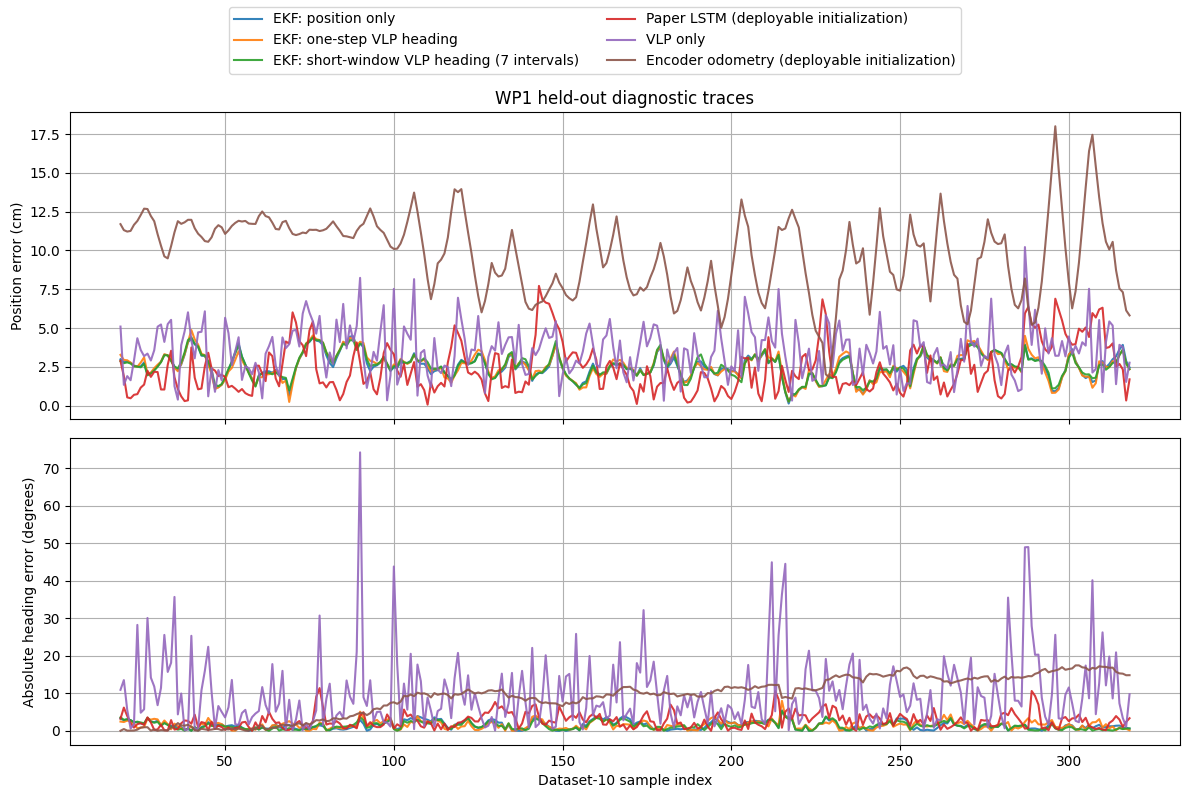

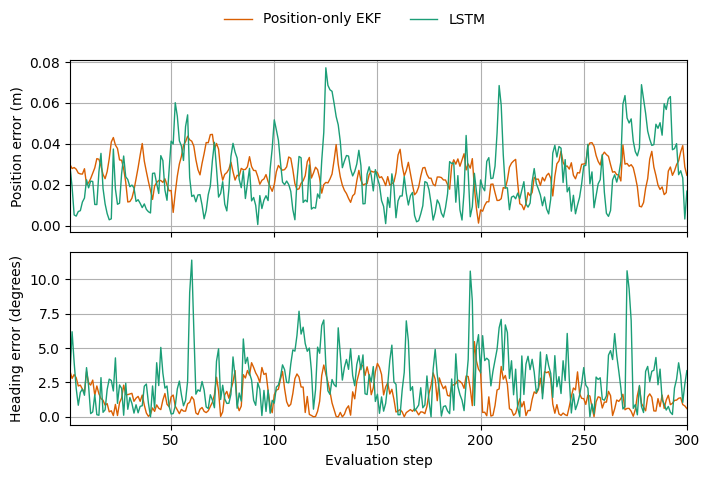

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for model_name in test_predictions:
    model_trace = test_traces[test_traces["model"] == model_name]
    axes[0].plot(
        model_trace["sample_index"],
        100 * model_trace["position_error_m"],
        label=model_name,
        alpha=0.9,
    )
    axes[1].plot(
        model_trace["sample_index"],
        model_trace["absolute_heading_error_deg"],
        label=model_name,
        alpha=0.9,
    )
axes[0].set_ylabel("Position error (cm)")
axes[1].set_ylabel("Absolute heading error (degrees)")
axes[1].set_xlabel("Dataset-10 sample index")
axes[0].set_title("WP1 held-out diagnostic traces")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.91))
figure_path = WP1_OUTPUT / "held_out_error_traces.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

primary_trace = test_traces[test_traces["model"] == PRIMARY_VARIANT.name]
primary_trace.to_csv(WP1_OUTPUT / "primary_ekf_trace_for_wp9.csv", index=False)

# Focused, publication-sized trace for the direct classical comparison.
comparison_names = [PRIMARY_VARIANT.name, "Paper LSTM (deployable initialization)"]
comparison_styles = {
    PRIMARY_VARIANT.name: {"label": "Position-only EKF", "color": "#d95f02"},
    "Paper LSTM (deployable initialization)": {"label": "LSTM", "color": "#1b9e77"},
}
fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.8), sharex=True)
for model_name in comparison_names:
    model_trace = test_traces[test_traces["model"] == model_name].reset_index(drop=True)
    style = comparison_styles[model_name]
    steps = np.arange(1, len(model_trace) + 1)
    axes[0].plot(steps, model_trace["position_error_m"], linewidth=1.0, **style)
    axes[1].plot(steps, model_trace["absolute_heading_error_deg"], linewidth=1.0, **style)
axes[0].set_ylabel("Position error (m)")
axes[1].set_ylabel("Heading error (degrees)")
axes[1].set_xlabel("Evaluation step")
axes[0].set_xlim(1, EVALUATION_SAMPLES)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
comparison_figure_path = WP1_OUTPUT / "offline_lstm_primary_ekf_error_traces.png"
fig.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Protocol and numerical consistency checks.
assert len(common_indices) == EVALUATION_SAMPLES
assert set(test_metrics["samples"]) == {EVALUATION_SAMPLES, 100}
assert test_metrics[
    ["position_median_m", "position_p90_m", "heading_median_deg", "heading_p90_deg"]
].notna().all().all()
assert (test_metrics["position_p90_m"] >= test_metrics["position_median_m"]).all()
assert (test_metrics["heading_p90_deg"] >= test_metrics["heading_median_deg"]).all()
for covariance in [
    *process_covariances.values(),
    *measurement_covariances.values(),
]:
    assert np.linalg.eigvalsh(covariance).min() > 0

# Test-run ground truth must not enter EKF or LSTM inference. Deliberately corrupt
# those columns and verify that predictions remain unchanged.
truth_corrupted_test_frame = test_frame.copy()
truth_corrupted_test_frame[["x_hist", "y_hist", "heading_hist_rad"]] = np.nan
for variant in test_variants:
    repeated_prediction = run_ekf(truth_corrupted_test_frame, variant)
    assert np.allclose(
        repeated_prediction.loc[common_indices].to_numpy(),
        test_predictions[variant.name].loc[common_indices].to_numpy(),
        equal_nan=True,
    )
repeated_rnn_prediction = predict_rnn_with_deployable_initialization(
    truth_corrupted_test_frame
)
assert np.allclose(
    repeated_rnn_prediction.loc[common_indices].to_numpy(),
    test_predictions["Paper LSTM (deployable initialization)"].loc[
        common_indices
    ].to_numpy(),
    rtol=1e-5,
    atol=1e-7,
)

all_segment = test_metrics[test_metrics["segment"] == "all"].copy()
best_position = all_segment.loc[all_segment["position_median_m"].idxmin()]
best_heading = all_segment.loc[all_segment["heading_median_deg"].idxmin()]

provenance = {
    **environment,
    "model_sha256": model_metadata["sha256"],
    "selected_short_window": SELECTED_SHORT_WINDOW,
    "available_post_window_samples": len(available_common_indices),
    "held_out_samples": len(common_indices),
    "evaluation_raw_index_start": int(common_indices[0]),
    "evaluation_raw_index_end": int(common_indices[-1]),
    "best_all_sample_position_median_model": best_position["model"],
    "best_all_sample_heading_median_model": best_heading["model"],
}
with (WP1_OUTPUT / "provenance.json").open("w") as handle:
    json.dump(provenance, handle, indent=2)

methods_note = "# WP1 EKF comparison\n\n"
methods_note += (
    "The primary filter uses VLP position only. Secondary filters use one-step "
    f"and {SELECTED_SHORT_WINDOW}-interval line-fit VLP heading. Process and full "
    "measurement covariances were estimated on manuscript datasets 1--8; dataset "
    "9 selected only the short window; dataset 10 was held out. Both EKF and LSTM "
    "were initialized from the first two usable VLP fixes, without Vive state. "
    "Results use common samples and circular heading error. The EKF comparison is "
    "offline; no closed-loop EKF run was recorded.\n\n"
    f"The comparison uses the first {len(common_indices)} post-window samples "
    f"from dataset 10 (raw zero-based indices {common_indices[0]}--{common_indices[-1]}). The "
    f"lowest all-sample median position error was produced by {best_position['model']}; "
    f"the lowest median heading error was produced by {best_heading['model']}. "
    "Refer to held_out_metrics.csv for values and segment-specific comparisons.\n"
)
(WP1_OUTPUT / "methods_and_scope.md").write_text(methods_note)
run_summary.to_csv(WP1_OUTPUT / "run_provenance.csv")

sorted(path.name for path in WP1_OUTPUT.iterdir())

['frozen_configuration.json',
 'held_out_error_traces.csv',
 'held_out_error_traces.png',
 'held_out_metrics.csv',
 'held_out_metrics_table.tex',
 'methods_and_scope.md',
 'offline_lstm_primary_ekf_error_traces.png',
 'primary_ekf_trace_for_wp9.csv',
 'provenance.json',
 'run_provenance.csv',
 'validation_window_selection.csv']

## WP1 interpretation guardrails

- The primary position-only EKF is the headline classical baseline.
- The heading-augmented filters are sensitivity variants because their heading and
  position observations come from the same VLP fixes.
- The result supports only an offline comparison on manuscript dataset 10.
- Any final claim must quote `held_out_metrics.csv`, use median/P90 consistently,
  and state separately which method is better for position and heading.
- WP5 will later report the startup transient and compare deployable initialization
  with the originally stored initialization in more detail.

# WP2 -- Synthetic estimator stress test (R1.4)

The protocol below freezes translation/rotation classes, recovery thresholds, a
50-step horizon, a 20-step residual window, and a 10-step within-class exclusion
before evaluating the saved LSTM. Dataset 10 is spliced so VLP and ground truth
jump to a later recorded pose while encoder pose features continue from the
pre-splice state using the post-splice commands. VLP heading features are
recomputed across the discontinuity.

Do not describe these dependent synthetic sequences as repeated live trials or as
evidence of controller recovery.

The selected sequences reuse one trajectory and are therefore non-independent
offline estimator tests, not repeated live trials or controller-recovery evidence.

In [11]:
analysis_module_dir = REVISION_ROOT / "revision_round_1" / "analysis"
if str(analysis_module_dir) not in sys.path:
    sys.path.insert(0, str(analysis_module_dir))
from reviewer_revision_work_packages import (
    run_heading_uncertainty, run_wp2_stress_test,
    run_wp3_fingerprint_comparison, run_wp4_source_gain_sensitivity,
)

wp2_summary, wp2_event_results = run_wp2_stress_test(
    ROBOT_VLP_ROOT, OUTPUT_ROOT, rnn_model=paper_rnn
)
wp2_summary

,scenario,events,non_recovery_fraction,recovery_steps_median,recovery_steps_q1,recovery_steps_q3,residual_position_median_m,residual_position_q1_m,residual_position_q3_m,residual_heading_median_deg,residual_heading_q1_deg,residual_heading_q3_deg
0,translation only,10,0.2,3.0,1.0,14.50,0.030147,0.024594,0.040157,1.814669,1.550158,3.069447
1,rotation only,10,0.3,13.0,12.0,20.50,0.023875,0.019472,0.035286,2.251268,2.195033,4.837239
2,combined,10,0.4,19.0,17.5,21.25,0.029892,0.023264,0.038060,5.575027,3.210781,8.226409


# WP3 -- Fingerprint regressor comparison (R1.6)

Compare the saved feedforward fingerprint model with inverse-distance-weighted kNN
and separate x/y Gaussian-process regressors on the same CNC training grid and
independent validation set. Select k using training-only cross-validation and fit GP
hyperparameters without validation targets. Report median, RMSE, P90, and maximum
radial error plus consistently measured or estimated memory and query cost.

The comparison uses the paper's 1,517-point CNC training grid and independent
528-point perturbed-grid validation set. Validation targets are not used to select
kNN or GP hyperparameters. Memory is serialized artifact size and latency is a
same-host CPU batch measurement, not an embedded benchmark.

In [12]:
wp3_results, wp3_configuration = run_wp3_fingerprint_comparison(
    ROBOT_VLP_ROOT, OUTPUT_ROOT
)
wp3_results

,method,samples,position_median_m,position_rmse_m,position_p90_m,position_max_m,serialized_memory_kib,median_batched_query_ms
0,Feedforward network,528,0.018801,0.023686,0.034619,0.081644,58.723633,0.003780
1,IDW kNN,528,0.020716,0.025095,0.037151,0.076199,90.338867,0.001420
2,Gaussian process,528,0.022449,0.025172,0.033796,0.065415,36107.319336,0.063189


# WP4 -- RSS-feature sensitivity and illumination scope (R2.5)

Dataset 10 contains the four stored carrier-peak amplitudes, so systematic common
and single-carrier scaling and random multiplicative perturbations can be applied
before re-running the saved fingerprint model and LSTM. The submitted paper's
Vive-aligned offline encoder features are held fixed across conditions.

The perturbations follow capture normalization and FFT extraction. Uniform scaling
of a waveform cancels under peak normalization, while changing one source can also
change the other normalized features. This analysis therefore tests RSS-feature
sensitivity rather than physical source/receiver gain or ambient illumination.
Shot noise, saturation, and near-carrier interference were not simulated.

In [13]:
wp4_compact_results, wp4_random_summary = run_wp4_source_gain_sensitivity(
    ROBOT_VLP_ROOT, OUTPUT_ROOT, rnn_model=paper_rnn
)
display(wp4_compact_results)
wp4_random_summary

,condition,gain_target,gain_factor,method,samples,position_median_m,position_rmse_m,position_p90_m,position_max_m,heading_median_deg,heading_p90_deg
0,baseline,none,1.00,VLP only,300,0.035456,0.038913,0.055302,0.102184,7.429611,20.591548
1,baseline,none,1.00,LSTM fusion,300,0.017825,0.022906,0.034854,0.063362,1.656020,4.033420
2,all LEDs -20%,all LEDs,0.80,VLP only,300,0.085630,0.093863,0.130407,0.210817,9.010474,23.968540
3,all LEDs -20%,all LEDs,0.80,LSTM fusion,300,0.030016,0.036244,0.054747,0.096984,2.003761,5.166919
4,all LEDs -10%,all LEDs,0.90,VLP only,300,0.048192,0.056460,0.083121,0.150793,7.405840,19.877688
5,all LEDs -10%,all LEDs,0.90,LSTM fusion,300,0.017555,0.022661,0.034266,0.064480,1.498932,3.596980
6,all LEDs -5%,all LEDs,0.95,VLP only,300,0.040034,0.045306,0.065230,0.117958,7.423621,20.435385
7,all LEDs -5%,all LEDs,0.95,LSTM fusion,300,0.016095,0.020846,0.033268,0.057138,1.473547,3.839715
8,all LEDs +5%,all LEDs,1.05,VLP only,300,0.033114,0.036948,0.053944,0.101127,7.790934,21.779319
9,all LEDs +5%,all LEDs,1.05,LSTM fusion,300,0.021254,0.026533,0.040853,0.064188,1.908325,4.283222


,sigma_fraction,method,position_median_m,position_median_q1_m,position_median_q3_m,position_p90_m,heading_median_deg,heading_p90_deg
0,0.02,LSTM fusion,0.018198,0.017912,0.018480,0.036119,1.746748,4.093080
1,0.02,VLP only,0.035495,0.035006,0.036057,0.057080,7.838159,21.410526
2,0.05,LSTM fusion,0.018949,0.018663,0.019525,0.036750,2.119852,4.936347
3,0.05,VLP only,0.037297,0.036254,0.038062,0.063075,9.927269,26.234884
4,0.10,LSTM fusion,0.022551,0.021707,0.024138,0.043892,2.847941,7.568947
5,0.10,VLP only,0.043833,0.042693,0.045648,0.080093,14.678590,39.265558


# WP5 -- Deployable initialization sensitivity (R1.8)

This standalone offline analysis reconstructs the initialization used for the
original paper result and compares it with a deployable VLP-only alternative. The
original evaluation applied one constant correction to the encoder $x$, $y$, and
heading histories so that they exactly matched Vive at raw sample 19, the endpoint
of the first 20-sample LSTM window. The deployable condition instead starts at the
first finite VLP position, obtains heading from the first sufficiently displaced
VLP fix, holds position during that two-fix warm-up, and re-integrates encoder
increments without reading Vive. The saved LSTM, VLP inputs, feature order,
normalization, windows, and 300 held-out samples are unchanged.

Encoder odometry is included as a diagnostic because these are the three LSTM
features affected by initialization. VLP itself is unchanged, and the live
experiments are not recomputed. The first-20-prediction segment is reported as a
descriptive startup window; no post-hoc recovery threshold is introduced.


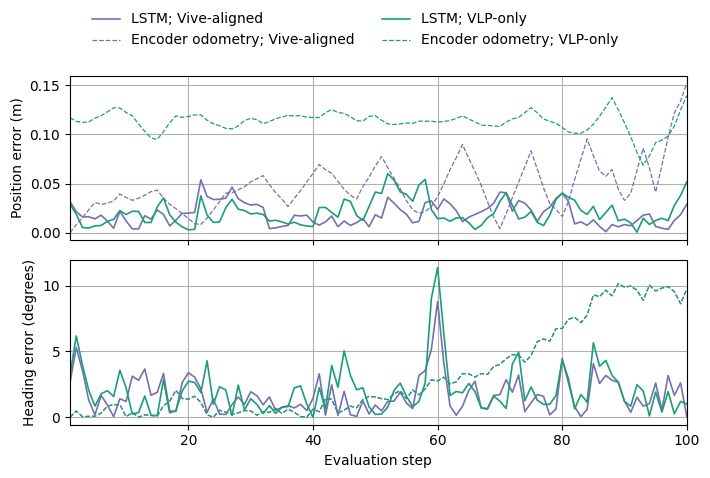

,segment,initialization,estimator,samples,position_median_m,position_p90_m,heading_median_deg,heading_p90_deg
0,all,Vive-aligned (original offline evaluation),LSTM,300,0.017825,0.034854,1.656012,4.033423
1,first_20,Vive-aligned (original offline evaluation),LSTM,20,0.016184,0.021888,1.782701,3.555341
2,first_100,Vive-aligned (original offline evaluation),LSTM,100,0.017884,0.034346,1.402651,3.326917
3,last_100,Vive-aligned (original offline evaluation),LSTM,100,0.019041,0.039526,1.675449,4.053271
4,all,Vive-aligned (original offline evaluation),Encoder odometry,300,0.060725,0.132476,9.911146,15.230124
5,first_20,Vive-aligned (original offline evaluation),Encoder odometry,20,0.030371,0.039579,0.329973,1.376957
6,first_100,Vive-aligned (original offline evaluation),Encoder odometry,100,0.042340,0.076419,1.566750,9.557438
7,last_100,Vive-aligned (original offline evaluation),Encoder odometry,100,0.087023,0.164515,14.525595,16.779243
8,all,VLP-only deployable,LSTM,300,0.020529,0.046341,2.302746,5.066651
9,first_20,VLP-only deployable,LSTM,20,0.012590,0.026561,1.886448,3.610662


In [14]:
WP5_OUTPUT = OUTPUT_ROOT / "WP5_initialization"
WP5_OUTPUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_ALIGNMENT_INDEX = RNN_WINDOW - 1
WP5_SEGMENT_LENGTH = 20


def with_original_vive_alignment(frame, alignment_index=ORIGINAL_ALIGNMENT_INDEX):
    """Reproduce the constant patch used by the original paper evaluation code."""
    result = frame.copy()
    encoder_columns = ["encoder_x_hist", "encoder_y_hist", "encoder_heading_hist_rad"]
    truth_columns = ["x_hist", "y_hist", "heading_hist_rad"]
    patch = (
        result.loc[alignment_index, truth_columns].to_numpy(dtype=float)
        - result.loc[alignment_index, encoder_columns].to_numpy(dtype=float)
    )
    result[encoder_columns] = result[encoder_columns].to_numpy(dtype=float) + patch
    return result, patch


def predict_rnn_from_features(frame):
    windows = make_rnn_windows(frame)
    predicted_xy, predicted_heading_vector = paper_rnn.predict(windows, verbose=0)
    predicted_heading = np.arctan2(
        predicted_heading_vector[:, 0], predicted_heading_vector[:, 1]
    )
    target_index = frame.index[RNN_WINDOW - 1 :].to_numpy()
    return pd.DataFrame(
        {
            "x": predicted_xy[:, 0],
            "y": predicted_xy[:, 1],
            "heading": predicted_heading,
        },
        index=target_index,
    )


original_frame, original_patch = with_original_vive_alignment(test_frame)
wp5_deployable_frame = with_deployable_encoder_initialization(test_frame)
initialization_frames = {
    "Vive-aligned (original offline evaluation)": original_frame,
    "VLP-only deployable": wp5_deployable_frame,
}

wp5_predictions = {}
for initialization_name, initialized_frame in initialization_frames.items():
    wp5_predictions[(initialization_name, "LSTM")] = predict_rnn_from_features(
        initialized_frame
    )
    wp5_predictions[(initialization_name, "Encoder odometry")] = pd.DataFrame(
        {
            "x": initialized_frame["encoder_x_hist"],
            "y": initialized_frame["encoder_y_hist"],
            "heading": initialized_frame["encoder_heading_hist_rad"],
        },
        index=initialized_frame.index,
    )

wp5_indices = common_indices.copy()
wp5_segments = {
    "all": wp5_indices,
    "first_20": wp5_indices[:WP5_SEGMENT_LENGTH],
    "first_100": wp5_indices[:100],
    "last_100": wp5_indices[-100:],
}

wp5_metric_rows = []
wp5_trace_rows = []
for (initialization_name, estimator), prediction in wp5_predictions.items():
    position_errors, angular_errors = evaluate_prediction(
        test_frame, prediction, wp5_indices
    )
    for evaluation_step, sample_index, pos_error, ang_error in zip(
        np.arange(1, len(wp5_indices) + 1),
        wp5_indices,
        position_errors,
        angular_errors,
    ):
        estimate = prediction.loc[sample_index]
        wp5_trace_rows.append(
            {
                "evaluation_step": int(evaluation_step),
                "sample_index": int(sample_index),
                "initialization": initialization_name,
                "estimator": estimator,
                "x": float(estimate["x"]),
                "y": float(estimate["y"]),
                "heading_rad": float(estimate["heading"]),
                "position_error_m": float(pos_error),
                "heading_error_rad": float(ang_error),
                "absolute_heading_error_deg": float(np.degrees(abs(ang_error))),
            }
        )
    for segment_name, indices in wp5_segments.items():
        pos, ang = evaluate_prediction(test_frame, prediction, indices)
        wp5_metric_rows.append(
            {
                "file_run": TEST_RUN,
                "manuscript_dataset": TEST_RUN + 1,
                "role": "held out",
                "segment": segment_name,
                "initialization": initialization_name,
                "estimator": estimator,
                **summarize_errors(pos, ang),
            }
        )

wp5_metrics = pd.DataFrame(wp5_metric_rows)
wp5_traces = pd.DataFrame(wp5_trace_rows)
wp5_metrics.to_csv(WP5_OUTPUT / "initialization_metrics.csv", index=False)
wp5_traces.to_csv(WP5_OUTPUT / "initialization_error_traces.csv", index=False)

first_vlp_index, second_vlp_index, first_vlp_position, first_vlp_heading = (
    first_vlp_initialization(test_frame)
)
initialization_offsets = []
for initialization_name, initialized_frame in initialization_frames.items():
    initialized_pose = initialized_frame.loc[
        ORIGINAL_ALIGNMENT_INDEX,
        ["encoder_x_hist", "encoder_y_hist", "encoder_heading_hist_rad"],
    ].to_numpy(dtype=float)
    true_pose = test_frame.loc[
        ORIGINAL_ALIGNMENT_INDEX, ["x_hist", "y_hist", "heading_hist_rad"]
    ].to_numpy(dtype=float)
    initialization_offsets.append(
        {
            "initialization": initialization_name,
            "comparison_sample_index": ORIGINAL_ALIGNMENT_INDEX,
            "x_error_m": float(initialized_pose[0] - true_pose[0]),
            "y_error_m": float(initialized_pose[1] - true_pose[1]),
            "position_error_m": float(np.linalg.norm(initialized_pose[:2] - true_pose[:2])),
            "heading_error_deg": float(
                np.degrees(wrap_angle(initialized_pose[2] - true_pose[2]))
            ),
        }
    )
initialization_offsets = pd.DataFrame(initialization_offsets)
initialization_offsets.to_csv(WP5_OUTPUT / "initial_pose_offsets.csv", index=False)

table_export = wp5_metrics[
    (wp5_metrics["estimator"] == "LSTM")
    & (wp5_metrics["segment"].isin(["all", "first_20"]))
][
    [
        "segment",
        "initialization",
        "samples",
        "position_median_m",
        "position_p90_m",
        "heading_median_deg",
        "heading_p90_deg",
    ]
].copy()
table_export["segment"] = table_export["segment"].map(
    {"all": "All 300", "first_20": "First 20"}
)
table_export.columns = [
    "Segment",
    "Initialization",
    "$N$",
    "Median position (m)",
    "$P_{90}$ position (m)",
    "Median heading ($^\\circ$)",
    "$P_{90}$ heading ($^\\circ$)",
]
(WP5_OUTPUT / "initialization_comparison_table.tex").write_text(
    table_export.to_latex(
        index=False,
        escape=False,
        float_format=lambda value: f"{value:.4f}",
        column_format="llrrrrr",
    )
)

initialization_styles = {
    "Vive-aligned (original offline evaluation)": {
        "label": "Vive-aligned",
        "color": "#7570b3",
    },
    "VLP-only deployable": {"label": "VLP-only", "color": "#1b9e77"},
}
estimator_styles = {
    "LSTM": {"linestyle": "-", "linewidth": 1.2},
    "Encoder odometry": {"linestyle": "--", "linewidth": 0.9},
}
fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.8), sharex=True)
for (initialization_name, estimator), _ in wp5_predictions.items():
    trace = wp5_traces[
        (wp5_traces["initialization"] == initialization_name)
        & (wp5_traces["estimator"] == estimator)
    ].iloc[:100]
    init_style = initialization_styles[initialization_name]
    estimator_style = estimator_styles[estimator]
    label = f"{estimator}; {init_style['label']}"
    axes[0].plot(
        trace["evaluation_step"],
        trace["position_error_m"],
        label=label,
        color=init_style["color"],
        **estimator_style,
    )
    axes[1].plot(
        trace["evaluation_step"],
        trace["absolute_heading_error_deg"],
        label=label,
        color=init_style["color"],
        **estimator_style,
    )
axes[0].set_ylabel("Position error (m)")
axes[1].set_ylabel("Heading error (degrees)")
axes[1].set_xlabel("Evaluation step")
axes[0].set_xlim(1, 100)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.88))
wp5_figure_path = WP5_OUTPUT / "initialization_transient.png"
fig.savefig(wp5_figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Reproducibility and leakage checks.
original_anchor_pose = original_frame.loc[
    ORIGINAL_ALIGNMENT_INDEX,
    ["encoder_x_hist", "encoder_y_hist", "encoder_heading_hist_rad"],
].to_numpy(dtype=float)
truth_anchor_pose = test_frame.loc[
    ORIGINAL_ALIGNMENT_INDEX, ["x_hist", "y_hist", "heading_hist_rad"]
].to_numpy(dtype=float)
assert np.allclose(original_anchor_pose, truth_anchor_pose)
assert np.allclose(
    wp5_predictions[("VLP-only deployable", "LSTM")].loc[wp5_indices].to_numpy(),
    test_predictions["Paper LSTM (deployable initialization)"].loc[
        wp5_indices
    ].to_numpy(),
    rtol=1e-5,
    atol=1e-7,
)
truth_corrupted_wp5_frame = test_frame.copy()
truth_corrupted_wp5_frame[["x_hist", "y_hist", "heading_hist_rad"]] = np.nan
deployable_without_truth = predict_rnn_with_deployable_initialization(
    truth_corrupted_wp5_frame
)
assert np.allclose(
    deployable_without_truth.loc[wp5_indices].to_numpy(),
    wp5_predictions[("VLP-only deployable", "LSTM")].loc[wp5_indices].to_numpy(),
    rtol=1e-5,
    atol=1e-7,
)
assert len(wp5_indices) == EVALUATION_SAMPLES
assert wp5_metrics[
    ["position_median_m", "position_p90_m", "heading_median_deg", "heading_p90_deg"]
].notna().all().all()

wp5_provenance = {
    **environment,
    "protocol": "WP5 initialization sensitivity",
    "model_sha256": model_metadata["sha256"],
    "dataset_sha256": run_summary.loc[TEST_RUN, "sha256"],
    "held_out_file_run": TEST_RUN,
    "manuscript_dataset": TEST_RUN + 1,
    "evaluation_raw_index_start": int(wp5_indices[0]),
    "evaluation_raw_index_end": int(wp5_indices[-1]),
    "evaluation_samples": len(wp5_indices),
    "original_alignment_index": ORIGINAL_ALIGNMENT_INDEX,
    "original_encoder_patch": {
        "x_m": float(original_patch[0]),
        "y_m": float(original_patch[1]),
        "heading_rad": float(original_patch[2]),
        "heading_deg": float(np.degrees(original_patch[2])),
    },
    "vlp_first_fix_index": int(first_vlp_index),
    "vlp_heading_fix_index": int(second_vlp_index),
    "minimum_vlp_heading_baseline_m": MIN_HEADING_BASELINE_M,
    "startup_segment_predictions": WP5_SEGMENT_LENGTH,
    "threshold_metric": None,
    "threshold_reason": "No externally justified recovery threshold was available; descriptive startup errors are reported instead.",
}
with (WP5_OUTPUT / "provenance.json").open("w") as handle:
    json.dump(wp5_provenance, handle, indent=2)

lstm_summary = wp5_metrics[
    (wp5_metrics["estimator"] == "LSTM")
    & (wp5_metrics["segment"].isin(["all", "first_20"]))
].copy()
methods_note = "# WP5 initialization sensitivity\n\n"
methods_note += (
    "This standalone offline analysis compares the original paper's Vive-aligned "
    "encoder features with a VLP-only deployable initialization on manuscript "
    "dataset 10. The original condition reproduces the historical constant patch "
    f"at raw sample {ORIGINAL_ALIGNMENT_INDEX}; the deployable condition reads no "
    "Vive state. The saved LSTM is unchanged and both conditions use the same "
    f"{len(wp5_indices)} samples (raw indices {wp5_indices[0]}--{wp5_indices[-1]}). "
    "Encoder odometry is retained only as a diagnostic. The first 20 predictions "
    "are a descriptive startup segment; no recovery threshold was selected after "
    "viewing held-out results. The recorded live trials were not recomputed.\n"
)
(WP5_OUTPUT / "methods_and_scope.md").write_text(methods_note)

display_columns = [
    "segment",
    "initialization",
    "estimator",
    "samples",
    "position_median_m",
    "position_p90_m",
    "heading_median_deg",
    "heading_p90_deg",
]
wp5_metrics[display_columns]


# WP6 -- LSTM/odometry crossover horizon (R1.9)

## Frozen protocol

This analysis uses the same 300-sample live error windows as the manuscript: rows
20--319 from each LSTM-controlled trial and rows 0--299 from the corresponding
encoder-controlled trial. These are separate closed-loop runs of the same nominal
path, not paired predictions on one trajectory.

For each trace, a trailing 20-step median position error is calculated. A sustained
crossover is the earliest one-based evaluation step at which the LSTM rolling
median is strictly below the encoder rolling median and remains below it at every
subsequent evaluated step. The first rolling statistic is available at step 20; a
path is reported as having no sustained crossover if the criterion is never met.
No window width, inequality, or persistence rule is selected after inspecting the
results.

Distance is reconstructed independently for each closed-loop trial by summing
successive Vive ground-truth displacements from the start of its analyzed window.
Because the two estimators controlled separate runs, the manuscript reports the
narrow range spanned by those two distances rather than treating either run as the
other estimator's travelled distance. The result is descriptive of these recorded
paths and is not a universal switching threshold.

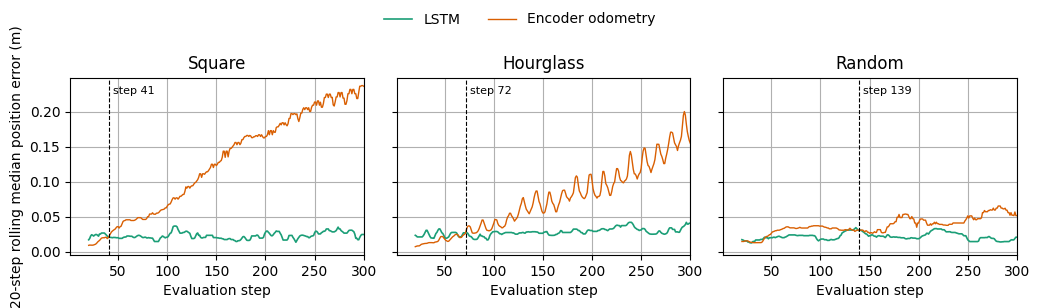

,path,crossover_status,crossover_evaluation_step_1_based,crossover_trace_index_0_based,lstm_vive_distance_m,encoder_vive_distance_m,distance_min_m,distance_max_m,lstm_rolling_median_at_crossover_m,encoder_rolling_median_at_crossover_m,rolling_window_steps,evaluation_samples,lstm_final_rolling_median_m,encoder_final_rolling_median_m
0,Square,Sustained crossover observed,41,40,4.422829,4.445275,4.422829,4.445275,0.020701,0.023107,20,300,0.024799,0.236359
1,Hourglass,Sustained crossover observed,72,71,7.859338,7.882930,7.859338,7.882930,0.027142,0.031401,20,300,0.040894,0.155137
2,Random,Sustained crossover observed,139,138,15.215358,15.182386,15.182386,15.215358,0.030184,0.030962,20,300,0.020950,0.051694


In [15]:
WP6_OUTPUT = OUTPUT_ROOT / "WP6_crossover"
WP6_OUTPUT.mkdir(parents=True, exist_ok=True)

LIVE_RESULT_DIR = ROBOT_VLP_ROOT / "notebooks" / "exploratory"
WP6_ROLLING_WINDOW = 20
WP6_EVALUATION_SAMPLES = 300
WP6_LSTM_START_ROW = 20
WP6_ENCODER_START_ROW = 0

live_path_files = {
    "Square": {
        "lstm": "final_rnn_square_m3_2.csv",
        "encoder": "final_encoder_square_m3.csv",
    },
    "Hourglass": {
        "lstm": "final_rnn_hourglass_m3.csv",
        "encoder": "final_encoder_hourglass_m3.csv",
    },
    "Random": {
        "lstm": "final_rnn_random_m3_2.csv",
        "encoder": "final_encoder_random_m3.csv",
    },
}


def live_position_error(frame, x_column, y_column):
    return np.hypot(
        frame[x_column].to_numpy(dtype=float) - frame["real_x"].to_numpy(dtype=float),
        frame[y_column].to_numpy(dtype=float) - frame["real_y"].to_numpy(dtype=float),
    )


def cumulative_vive_distance(frame):
    xy = frame[["real_x", "real_y"]].to_numpy(dtype=float)
    increments = np.linalg.norm(np.diff(xy, axis=0), axis=1)
    return np.r_[0.0, np.cumsum(increments)]


def first_sustained_crossover(lstm_rolling, encoder_rolling):
    valid = np.isfinite(lstm_rolling) & np.isfinite(encoder_rolling)
    lower = valid & (lstm_rolling < encoder_rolling)
    sustained = np.logical_and.accumulate(lower[::-1])[::-1]
    indices = np.flatnonzero(sustained)
    return None if len(indices) == 0 else int(indices[0])


wp6_summary_rows = []
wp6_trace_rows = []
wp6_source_hashes = {}

for path_name, filenames in live_path_files.items():
    lstm_path = LIVE_RESULT_DIR / filenames["lstm"]
    encoder_path = LIVE_RESULT_DIR / filenames["encoder"]
    wp6_source_hashes[path_name] = {
        "lstm_file": str(lstm_path),
        "lstm_sha256": sha256_file(lstm_path),
        "encoder_file": str(encoder_path),
        "encoder_sha256": sha256_file(encoder_path),
    }
    lstm_full = pd.read_csv(lstm_path)
    encoder_full = pd.read_csv(encoder_path)
    lstm_frame = lstm_full.iloc[
        WP6_LSTM_START_ROW : WP6_LSTM_START_ROW + WP6_EVALUATION_SAMPLES
    ].reset_index(drop=True)
    encoder_frame = encoder_full.iloc[
        WP6_ENCODER_START_ROW : WP6_ENCODER_START_ROW + WP6_EVALUATION_SAMPLES
    ].reset_index(drop=True)
    if len(lstm_frame) != WP6_EVALUATION_SAMPLES or len(encoder_frame) != WP6_EVALUATION_SAMPLES:
        raise ValueError(f"{path_name}: fewer than 300 samples in an analysis window")

    lstm_error = live_position_error(lstm_frame, "rnn_x", "rnn_y")
    encoder_error = live_position_error(
        encoder_frame, "encoder_x", "encoder_y"
    )
    if not np.isfinite(lstm_error).all() or not np.isfinite(encoder_error).all():
        raise ValueError(f"{path_name}: non-finite position errors in analysis window")

    lstm_rolling = (
        pd.Series(lstm_error)
        .rolling(WP6_ROLLING_WINDOW, min_periods=WP6_ROLLING_WINDOW)
        .median()
        .to_numpy()
    )
    encoder_rolling = (
        pd.Series(encoder_error)
        .rolling(WP6_ROLLING_WINDOW, min_periods=WP6_ROLLING_WINDOW)
        .median()
        .to_numpy()
    )
    crossover_index = first_sustained_crossover(lstm_rolling, encoder_rolling)
    lstm_distance = cumulative_vive_distance(lstm_frame)
    encoder_distance = cumulative_vive_distance(encoder_frame)

    for index in range(WP6_EVALUATION_SAMPLES):
        wp6_trace_rows.append(
            {
                "path": path_name,
                "evaluation_step_1_based": index + 1,
                "trace_index_0_based": index,
                "lstm_position_error_m": float(lstm_error[index]),
                "encoder_position_error_m": float(encoder_error[index]),
                "lstm_rolling_median_m": float(lstm_rolling[index]),
                "encoder_rolling_median_m": float(encoder_rolling[index]),
                "lstm_vive_distance_m": float(lstm_distance[index]),
                "encoder_vive_distance_m": float(encoder_distance[index]),
            }
        )

    if crossover_index is None:
        summary = {
            "path": path_name,
            "crossover_status": "No sustained crossover",
            "crossover_evaluation_step_1_based": np.nan,
            "crossover_trace_index_0_based": np.nan,
            "lstm_vive_distance_m": np.nan,
            "encoder_vive_distance_m": np.nan,
            "distance_min_m": np.nan,
            "distance_max_m": np.nan,
            "lstm_rolling_median_at_crossover_m": np.nan,
            "encoder_rolling_median_at_crossover_m": np.nan,
        }
    else:
        two_distances = [lstm_distance[crossover_index], encoder_distance[crossover_index]]
        summary = {
            "path": path_name,
            "crossover_status": "Sustained crossover observed",
            "crossover_evaluation_step_1_based": crossover_index + 1,
            "crossover_trace_index_0_based": crossover_index,
            "lstm_vive_distance_m": float(two_distances[0]),
            "encoder_vive_distance_m": float(two_distances[1]),
            "distance_min_m": float(min(two_distances)),
            "distance_max_m": float(max(two_distances)),
            "lstm_rolling_median_at_crossover_m": float(lstm_rolling[crossover_index]),
            "encoder_rolling_median_at_crossover_m": float(encoder_rolling[crossover_index]),
        }
    summary.update(
        {
            "rolling_window_steps": WP6_ROLLING_WINDOW,
            "evaluation_samples": WP6_EVALUATION_SAMPLES,
            "lstm_final_rolling_median_m": float(lstm_rolling[-1]),
            "encoder_final_rolling_median_m": float(encoder_rolling[-1]),
        }
    )
    wp6_summary_rows.append(summary)

wp6_summary = pd.DataFrame(wp6_summary_rows)
wp6_traces = pd.DataFrame(wp6_trace_rows)
wp6_summary.to_csv(WP6_OUTPUT / "crossover_results.csv", index=False)
wp6_traces.to_csv(WP6_OUTPUT / "rolling_error_traces.csv", index=False)

table_export = wp6_summary[
    [
        "path",
        "crossover_evaluation_step_1_based",
        "crossover_trace_index_0_based",
        "distance_min_m",
        "distance_max_m",
    ]
].copy()
table_export.columns = [
    "Path",
    "Evaluation step",
    "Trace index",
    "Minimum distance (m)",
    "Maximum distance (m)",
]
(WP6_OUTPUT / "crossover_table.tex").write_text(
    table_export.to_latex(
        index=False,
        float_format=lambda value: f"{value:.2f}",
        column_format="lrrrr",
    )
)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.1), sharex=True, sharey=True)
for axis, path_name in zip(axes, live_path_files):
    trace = wp6_traces[wp6_traces["path"] == path_name]
    result = wp6_summary[wp6_summary["path"] == path_name].iloc[0]
    axis.plot(
        trace["evaluation_step_1_based"],
        trace["lstm_rolling_median_m"],
        label="LSTM",
        color="#1b9e77",
        linewidth=1.2,
    )
    axis.plot(
        trace["evaluation_step_1_based"],
        trace["encoder_rolling_median_m"],
        label="Encoder odometry",
        color="#d95f02",
        linewidth=1.0,
    )
    if np.isfinite(result["crossover_evaluation_step_1_based"]):
        step = int(result["crossover_evaluation_step_1_based"])
        axis.axvline(step, color="black", linestyle="--", linewidth=0.8)
        axis.text(
            step + 4,
            0.95,
            f"step {step}",
            transform=axis.get_xaxis_transform(),
            va="top",
            fontsize=8,
        )
    axis.set_title(path_name)
    axis.set_xlabel("Evaluation step")
    axis.set_xlim(1, WP6_EVALUATION_SAMPLES)
axes[0].set_ylabel("20-step rolling median position error (m)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.88))
wp6_figure_path = WP6_OUTPUT / "crossover_rolling_median.png"
fig.savefig(wp6_figure_path, dpi=300, bbox_inches="tight")
plt.show()

method_note = f"""# WP6 crossover-horizon method and scope

- Inputs: recorded live LSTM- and encoder-controlled square, hourglass, and random
  trials listed in `provenance.json`.
- Analysis windows: LSTM CSV rows 20--319 and encoder CSV rows 0--299, matching the
  300-sample windows used in the manuscript live-error comparison.
- Statistic: trailing {WP6_ROLLING_WINDOW}-step median position error.
- Crossover: earliest one-based evaluation step for which the LSTM rolling median
  is strictly lower than the encoder rolling median at that step and every later
  step through step {WP6_EVALUATION_SAMPLES}.
- Distance: cumulative Vive ground-truth displacement from the beginning of each
  analyzed trial window. LSTM and encoder distances are retained separately because
  they were separate closed-loop trials; the manuscript reports their range.
- Scope: descriptive of these three recorded paths. It is not a universal switch
  point and does not establish performance on another path, environment, or motion
  protocol.
"""
(WP6_OUTPUT / "methods_and_scope.md").write_text(method_note)

wp6_provenance = {
    **environment,
    "protocol": "WP6 live LSTM/encoder sustained crossover horizon",
    "rolling_window_steps": WP6_ROLLING_WINDOW,
    "evaluation_samples": WP6_EVALUATION_SAMPLES,
    "lstm_csv_row_start_inclusive": WP6_LSTM_START_ROW,
    "lstm_csv_row_end_inclusive": WP6_LSTM_START_ROW + WP6_EVALUATION_SAMPLES - 1,
    "encoder_csv_row_start_inclusive": WP6_ENCODER_START_ROW,
    "encoder_csv_row_end_inclusive": WP6_ENCODER_START_ROW + WP6_EVALUATION_SAMPLES - 1,
    "crossover_rule": (
        "earliest one-based evaluation step at which the trailing rolling median "
        "LSTM position error is strictly below encoder odometry and remains so "
        "through evaluation step 300"
    ),
    "distance_definition": (
        "cumulative Vive displacement from start of each estimator-specific "
        "analyzed live trial window"
    ),
    "sources": wp6_source_hashes,
}
(WP6_OUTPUT / "provenance.json").write_text(
    json.dumps(wp6_provenance, indent=2) + "\n"
)

assert len(wp6_traces) == len(live_path_files) * WP6_EVALUATION_SAMPLES
assert (wp6_summary["crossover_status"] == "Sustained crossover observed").all()
assert wp6_summary["crossover_evaluation_step_1_based"].tolist() == [41, 72, 139]
wp6_summary


# WP7 -- Training cost and latency evidence (R1.10, R1.11)

This audit separates four evidence classes: historical records, protocol-derived
calculations, measurements made during this revision, and unavailable intervals.
The navigation and live-result CSV files contain no timestamps, so a historical
end-to-end median or P90 cannot be reconstructed. Current-host measurements below
cover only FFT/peak extraction and warmed model calls; they are not presented as
the latency of the historical live system.

The archived acquisition loop takes three VLP captures per movement cycle. Values
are therefore reported per capture and, where useful, for the three-capture cycle.


In [16]:
import ast
import re
import subprocess
import time
import warnings

WP7_OUTPUT = OUTPUT_ROOT / "WP7_cost_latency"
WP7_OUTPUT.mkdir(parents=True, exist_ok=True)

HISTORICAL_TUNING_NOTEBOOK = (
    ROBOT_VLP_ROOT / "notebooks" / "exploratory" / "RNN_parameter_tuning.ipynb"
)
RAW_ROBOT_DIR = ROBOT_VLP_ROOT / "data" / "raw" / "experiments" / "Robot"
RAW_CNC_DIR = ROBOT_VLP_ROOT / "data" / "raw" / "experiments" / "CNC"
COMMUNICATION_SOURCE = ROBOT_VLP_ROOT / "robot_vlp" / "data_collection" / "communication.py"
ESP_VLP_SOURCE = ROBOT_VLP_ROOT / "esp code" / "vlp_read" / "vlp_read.ino"

# -----------------------------------------------------------------------------
# Historical training evidence
# -----------------------------------------------------------------------------
historical_nb = json.loads(HISTORICAL_TUNING_NOTEBOOK.read_text())
historical_source = "\n".join(
    "".join(cell.get("source", [])) for cell in historical_nb["cells"]
)
historical_output = "\n".join(
    "".join(output.get("text", []))
    for cell in historical_nb["cells"]
    for output in cell.get("outputs", [])
    if output.get("output_type") == "stream"
)
historical_output_clean = re.sub(r"\x1b\[[0-9;]*m", "", historical_output).replace("\r", "\n")

WINDOW_LENGTH_ARCHIVED = 25
window_counts = {
    run_id: len(runs[run_id]) - WINDOW_LENGTH_ARCHIVED + 1 for run_id in RUN_IDS
}
train_window_count = sum(window_counts[run_id] for run_id in TRAIN_RUNS)
validation_window_count = window_counts[VALIDATION_RUN]
held_out_window_count = window_counts[TEST_RUN]

epoch_numbers = [int(value) for value in re.findall(r"Epoch (\d+)/500", historical_output_clean)]
final_epoch_count = max(epoch_numbers)
epoch_summary_lines = [
    line for line in historical_output_clean.splitlines() if "374/374" in line
]
epoch_seconds = []
for line in epoch_summary_lines:
    match = re.search(r"374/374.*?\s(\d+)s\s+\d+ms/step", line)
    if match:
        epoch_seconds.append(int(match.group(1)))
displayed_training_seconds = sum(epoch_seconds)
assert len(epoch_seconds) == final_epoch_count
assert "tf.config.set_visible_devices([], 'GPU')" in historical_source

tuning_directories = {
    "architecture": ROBOT_VLP_ROOT / "notebooks/exploratory/rnn_tuning/rnn_random_search",
    "regularization": ROBOT_VLP_ROOT / "notebooks/exploratory/rnn_tuning_stage2/rnn_reg_tuning",
    "optimization": ROBOT_VLP_ROOT / "notebooks/exploratory/rnn_tuning_stage3/rnn_opt_tuning",
    "sequence length": ROBOT_VLP_ROOT / "notebooks/exploratory/rnn_tuning_stage4/rnn_extra_tuning",
}
tuning_rows = []
for stage, directory in tuning_directories.items():
    durations = []
    statuses = []
    for trial_file in sorted(directory.glob("trial_*/trial.json")):
        trial_record = json.loads(trial_file.read_text())
        statuses.append(trial_record.get("status", "UNKNOWN"))
        stat = trial_file.stat()
        if hasattr(stat, "st_birthtime") and stat.st_mtime >= stat.st_birthtime:
            durations.append(stat.st_mtime - stat.st_birthtime)
    tuning_rows.append(
        {
            "stage": stage,
            "completed_trials": statuses.count("COMPLETED"),
            "trial_files": len(statuses),
            "reconstructed_active_hours": sum(durations) / 3600,
            "trial_duration_median_min": np.median(durations) / 60,
            "trial_duration_p90_min": np.percentile(durations, 90) / 60,
        }
    )
tuning_summary = pd.DataFrame(tuning_rows)
total_tuning_trials = int(tuning_summary["completed_trials"].sum())
reconstructed_tuning_hours = float(tuning_summary["reconstructed_active_hours"].sum())

# -----------------------------------------------------------------------------
# Data-collection scale and a protocol-delay estimate
# -----------------------------------------------------------------------------
raw_training_paths = [RAW_ROBOT_DIR / f"exp1_{run_id}.csv" for run_id in TRAIN_RUNS]
raw_training_frames = [pd.read_csv(path, delimiter="|") for path in raw_training_paths]
raw_logged_cycles = sum(len(frame) for frame in raw_training_frames)
retained_vlp_cycles = sum(int(frame["vlp_data"].notna().sum()) for frame in raw_training_frames)
processed_training_rows = sum(len(runs[run_id]) for run_id in TRAIN_RUNS)
assert retained_vlp_cycles == processed_training_rows
assert train_window_count == 11958

# -----------------------------------------------------------------------------
# Frame-size evidence and protocol-derived serial/pacing values
# -----------------------------------------------------------------------------
payload_lengths = []
representative_frames = []
cnc_paths = [RAW_CNC_DIR / "cnc_fingerprint_01.csv", RAW_CNC_DIR / "cnc_fingerprint_02.csv"]
for cnc_path in cnc_paths:
    cnc_frame = pd.read_csv(cnc_path, delimiter="|")
    for encoded_captures in cnc_frame["vlp_data"]:
        for capture in ast.literal_eval(encoded_captures):
            if capture is None:
                continue
            values = [int(value) for value in capture]
            if len(values) != 512:
                continue
            if len(representative_frames) < 3:
                representative_frames.append(np.asarray(values, dtype=float))
            # ADC values are sent as comma-delimited decimal text by the archived firmware.
            payload_lengths.append(len(",".join(str(value) for value in values)))

payload_lengths = np.asarray(payload_lengths, dtype=int)
UART_BAUD = 460800
UART_BITS_PER_BYTE_8N1 = 10
uart_transfer_ms = payload_lengths * UART_BITS_PER_BYTE_8N1 / UART_BAUD * 1000
WIFI_CHUNK_BYTES = 50
WIFI_CHUNK_DELAY_MS = 10
wifi_chunk_pacing_ms = np.ceil(payload_lengths / WIFI_CHUNK_BYTES) * WIFI_CHUNK_DELAY_MS
median_payload_bytes = float(np.median(payload_lengths))
median_uart_ms = float(np.median(uart_transfer_ms))
median_wifi_pacing_ms = float(np.median(wifi_chunk_pacing_ms))

# This is an approximate protocol-delay subtotal from explicit sleeps/delays in the archived collection
# loop, not a measured experiment duration. Robot motion, command RTT, retries, and
# uninstrumented scheduling are excluded. UART/acquisition are not added because they
# may overlap the firmware's initial 50 ms wait.
vive_logging_sleep_s = raw_logged_cycles * 10 * 0.1
vlp_explicit_delay_s = retained_vlp_cycles * 3 * (
    0.020 + 0.050 + median_wifi_pacing_ms / 1000 + 0.100
)
collection_protocol_delay_subtotal_hours = (vive_logging_sleep_s + vlp_explicit_delay_s) / 3600

# -----------------------------------------------------------------------------
# Timestamp inventory
# -----------------------------------------------------------------------------
timestamp_sources = {
    **{f"raw navigation run {run_id}": raw_training_paths[run_id] for run_id in TRAIN_RUNS},
    **{f"processed navigation run {run_id}": run_paths[run_id] for run_id in RUN_IDS},
    **{
        f"live {path_name.lower()} {estimator}": LIVE_RESULT_DIR / filename
        for path_name, files in live_path_files.items()
        for estimator, filename in files.items()
    },
    "CNC fingerprint 01": cnc_paths[0],
    "CNC fingerprint 02": cnc_paths[1],
}
timestamp_rows = []
for label, path in timestamp_sources.items():
    separator = "|" if "data/raw/experiments" in str(path) else ","
    columns = pd.read_csv(path, delimiter=separator, nrows=0).columns.tolist()
    timestamp_columns = [column for column in columns if "time" in column.lower()]
    navigation_or_live = label.startswith("raw navigation") or label.startswith("processed navigation") or label.startswith("live ")
    timestamp_rows.append(
        {
            "source": label,
            "path": str(path),
            "timestamp_columns": ", ".join(timestamp_columns) if timestamp_columns else "none",
            "supports_navigation_end_to_end_interval": bool(timestamp_columns) and navigation_or_live,
        }
    )
timestamp_inventory = pd.DataFrame(timestamp_rows)
assert not timestamp_inventory["supports_navigation_end_to_end_interval"].any()

# -----------------------------------------------------------------------------
# Revision-host component profiling
# -----------------------------------------------------------------------------
if str(ROBOT_VLP_ROOT) not in sys.path:
    sys.path.insert(0, str(ROBOT_VLP_ROOT))
from robot_vlp.data_collection.communication import FFT_win, calc_pks
from robot_vlp.modeling.gen_cnc_vlp_model import load_vlp_models


def hardware_summary():
    try:
        output = subprocess.check_output(
            ["system_profiler", "SPHardwareDataType"], text=True, stderr=subprocess.DEVNULL
        )
    except Exception:
        return {"model": "unavailable", "chip": "unavailable", "memory": "unavailable"}
    wanted = {
        "Model Name": "model",
        "Chip": "chip",
        "Total Number of Cores": "cores",
        "Memory": "memory",
    }
    result = {}
    for line in output.splitlines():
        if ":" not in line:
            continue
        key, value = [part.strip() for part in line.split(":", 1)]
        if key in wanted:
            result[wanted[key]] = value
    return result


def benchmark(label, function, warmup, repeats):
    for _ in range(warmup):
        function()
    samples_ns = []
    for _ in range(repeats):
        start_ns = time.perf_counter_ns()
        function()
        samples_ns.append(time.perf_counter_ns() - start_ns)
    samples_ms = np.asarray(samples_ns, dtype=float) / 1e6
    return (
        {
            "component": label,
            "median_ms": float(np.median(samples_ms)),
            "p90_ms": float(np.percentile(samples_ms, 90)),
            "minimum_ms": float(samples_ms.min()),
            "maximum_ms": float(samples_ms.max()),
            "warmup_calls": warmup,
            "measured_calls": repeats,
        },
        samples_ms,
    )


def fft_three_capture_call():
    rss = [calc_pks(FFT_win(frame)[0]) for frame in representative_frames]
    return np.mean(rss, axis=0)


rss_probe = pd.DataFrame(
    [fft_three_capture_call()], columns=["L1", "L2", "L3", "L4"]
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    vlp_pipeline = load_vlp_models()["high_acc"]


def fingerprint_call():
    scaled = vlp_pipeline.scaler.transform(rss_probe)
    return vlp_pipeline.model.predict(scaled, verbose=0)


rnn_probe = np.nan_to_num(
    runs[TEST_RUN].loc[: RNN_WINDOW - 1, RNN_FEATURES].to_numpy(dtype=np.float32), nan=0.0
)[None, :, :]


def rnn_call():
    return paper_rnn.predict(rnn_probe, verbose=0)


profile_rows = []
profile_samples = []
with tf.device("/CPU:0"):
    for label, function, warmup, repeats in [
        ("FFT and peak extraction (three captures)", fft_three_capture_call, 50, 2000),
        ("Fingerprint standardization and Keras predict", fingerprint_call, 10, 200),
        ("LSTM Keras predict", rnn_call, 10, 200),
    ]:
        row, samples = benchmark(label, function, warmup, repeats)
        profile_rows.append(row)
        profile_samples.extend(
            {"component": label, "repeat": index + 1, "elapsed_ms": value}
            for index, value in enumerate(samples)
        )
profile_summary = pd.DataFrame(profile_rows)
profiling_samples = pd.DataFrame(profile_samples)

hardware = hardware_summary()
profiling_log = {
    **environment,
    "hardware": hardware,
    "device_policy": "TensorFlow calls placed on /CPU:0",
    "timer": "time.perf_counter_ns",
    "execution": "serial warmed single-sample Keras predict calls",
    "fft_scope": "three 512-sample captures plus four carrier-peak searches and averaging",
    "profile_summary": profile_rows,
}

# -----------------------------------------------------------------------------
# Retained tables and provenance
# -----------------------------------------------------------------------------
training_cost = pd.DataFrame(
    [
        ["Processed rows in datasets 1--8", processed_training_rows, "rows", "historical record", "Sum of processed CSV lengths"],
        ["Training windows", train_window_count, "windows", "historical record", "25-sample stride-1 windows within datasets 1--8"],
        ["Validation windows", validation_window_count, "windows", "historical record", "Dataset 9"],
        ["Held-out windows", held_out_window_count, "windows", "historical record", "Dataset 10"],
        ["Final training epochs", final_epoch_count, "epochs", "historical record", "Early stopping in saved notebook output"],
        ["Final batch size", 32, "samples", "historical record", "Saved notebook source"],
        ["Displayed final-fit duration", displayed_training_seconds / 60, "minutes", "reconstructed estimate", "Sum of integer per-epoch durations printed by Keras; exact cell wall time unavailable"],
        ["Historical training hardware", "CPU only; processor/RAM unavailable", "", "partly available", "GPU disabled in notebook; hardware identity was not logged"],
        ["Completed tuning trials", total_tuning_trials, "trials", "historical record", "200 + 200 + 200 + 5 completed trial records"],
        ["Active tuning time", reconstructed_tuning_hours, "hours", "reconstructed estimate", "Sum of trial-file creation-to-final-write intervals; excludes pauses and orchestration gaps"],
        ["Raw logged collection cycles, datasets 1--8", raw_logged_cycles, "cycles", "historical record", "Raw CSV rows, including cycles later excluded for missing VLP"],
        ["Retained VLP collection cycles, datasets 1--8", retained_vlp_cycles, "cycles", "historical record", "Raw rows containing VLP data; equals processed-row count"],
        ["Approximate collection protocol-delay subtotal", collection_protocol_delay_subtotal_hours, "hours", "protocol-derived estimate", "Explicit sleeps and representative median frame pacing; excludes motion, command RTT, retries, and scheduling"],
    ],
    columns=["item", "value", "unit", "evidence_class", "basis_and_limit"],
)

profile_lookup = profile_summary.set_index("component")
latency_components = pd.DataFrame(
    [
        ["ADC acquisition", "10.24 ms/capture; 30.72 ms for three", "fixed calculation", "512 samples / 50 kHz; assumes sequential captures"],
        ["UART ADC payload", f"{median_uart_ms:.2f} ms/capture at median payload; approximately {3 * median_uart_ms:.2f} ms for three", "protocol-derived estimate", f"{int(median_payload_bytes)} median bytes, 460800 baud, 8N1; observed payload range {payload_lengths.min()}--{payload_lengths.max()} bytes"],
        ["Firmware TCP chunk pacing", f"{median_wifi_pacing_ms:.0f} ms/capture at median payload; approximately {3 * median_wifi_pacing_ms / 1000:.2f} s for three", "protocol-derived estimate", "10 ms delay after each 50-byte chunk; this is pacing, not measured Wi-Fi RTT"],
        ["Python inter-capture pause", "100 ms/capture; 300 ms for three", "fixed from source", "Explicit sleep after every read"],
        ["Firmware stop/start waits", "70 ms/capture; 210 ms for three", "fixed from source", "20 ms stop wait plus 50 ms start-attempt wait; retries add more"],
        ["FFT and peak extraction", f"median {profile_lookup.loc['FFT and peak extraction (three captures)', 'median_ms']:.3f} ms; P90 {profile_lookup.loc['FFT and peak extraction (three captures)', 'p90_ms']:.3f} ms", "measured in revision", "Three captures on documented CPU host"],
        ["Fingerprint inference", f"median {profile_lookup.loc['Fingerprint standardization and Keras predict', 'median_ms']:.2f} ms; P90 {profile_lookup.loc['Fingerprint standardization and Keras predict', 'p90_ms']:.2f} ms", "measured in revision", "One warmed scaler + Keras predict call on documented CPU host"],
        ["LSTM inference", f"median {profile_lookup.loc['LSTM Keras predict', 'median_ms']:.2f} ms; P90 {profile_lookup.loc['LSTM Keras predict', 'p90_ms']:.2f} ms", "measured in revision", "One warmed Keras predict call on documented CPU host"],
        ["Wi-Fi transfer and host scheduling", "unavailable", "not recoverable", "Navigation/live CSVs contain no timing fields"],
        ["Robot command return and handling", "unavailable", "not recoverable", "No dispatch, acknowledgement, or completion timestamps"],
        ["Historical end-to-end movement-cycle latency", "unavailable", "not recoverable", "Components cannot be summed into a measured distribution; overlap and uninstrumented terms remain"],
        ["Embedded neural inference", "0.203--1.427 ms across boards", "vendor-tool estimate", "Exported neural graph only; excludes ADC, UART, FFT, communication, and control"],
    ],
    columns=["component", "reported_value", "evidence_class", "scope_and_limit"],
)

training_cost.to_csv(WP7_OUTPUT / "training_cost.csv", index=False)
tuning_summary.to_csv(WP7_OUTPUT / "tuning_stage_summary.csv", index=False)
timestamp_inventory.to_csv(WP7_OUTPUT / "timestamp_inventory.csv", index=False)
latency_components.to_csv(WP7_OUTPUT / "latency_components.csv", index=False)
profile_summary.to_csv(WP7_OUTPUT / "profiling_summary.csv", index=False)
profiling_samples.to_csv(WP7_OUTPUT / "profiling_samples.csv", index=False)
(WP7_OUTPUT / "profiling_log.json").write_text(json.dumps(profiling_log, indent=2) + "\n")

training_tex = training_cost[["item", "value", "unit", "evidence_class"]].copy()
(WP7_OUTPUT / "training_cost_table.tex").write_text(
    training_tex.to_latex(index=False, escape=True, column_format="llll")
)
latency_tex = latency_components.copy()
(WP7_OUTPUT / "latency_components_table.tex").write_text(
    latency_tex.to_latex(index=False, escape=True, column_format="llll")
)

wp7_method_note = f"""# WP7 training-cost and latency method and scope

## Training evidence

- Datasets 1--8 contain {processed_training_rows:,} processed rows and produce
  {train_window_count:,} run-bounded 25-sample, stride-1 windows.
- The saved final fit ran for {final_epoch_count} epochs at batch size 32. Summing
  Keras' integer per-epoch durations gives {displayed_training_seconds} s
  ({displayed_training_seconds / 60:.2f} min); the notebook does not retain exact
  cell wall-clock metadata.
- The notebook explicitly disabled GPU visibility, so training was CPU-only. The
  historical processor and RAM were not logged and are not inferred from the
  current computer.
- The four tuner directories contain {total_tuning_trials} completed trials.
  Creation-to-final-write intervals total {reconstructed_tuning_hours:.2f} h. This
  is an approximate active-trial total, not a recorded end-to-end search duration.
- Raw datasets 1--8 contain {raw_logged_cycles:,} logged cycles; {retained_vlp_cycles:,}
  have VLP data and were retained. Explicit delays in the archived loop imply an
  approximate {collection_protocol_delay_subtotal_hours:.1f} h protocol-delay subtotal. Robot
  motion, command/network round trips, retries, and scheduling, so total operating
  time was longer and cannot be recovered exactly.

## Latency evidence

- One 512-sample acquisition at 50 kHz is exactly 10.24 ms. The navigation loop
  requested three captures per movement cycle.
- UART values are calculated from 20,448 complete 512-sample frames in the two CNC
  files, decimal-text payload size, 460800 baud, and 8N1 framing. They are not
  measured time intervals.
- TCP chunk-pacing values come from the archived firmware's 10 ms delay per 50-byte
  chunk. They do not include actual Wi-Fi transfer time or host scheduling.
- FFT/peak extraction, fingerprint inference, and LSTM inference were newly measured
  with `time.perf_counter_ns` on {hardware.get('model', 'unavailable')},
  {hardware.get('chip', 'unavailable')}, {hardware.get('memory', 'unavailable')},
  using Python {environment['python']} and TensorFlow {environment['tensorflow']} on
  `/CPU:0`. These warmed, serial component timings are illustrative current-host
  measurements, not historical live-system timestamps.
- Navigation and live-result CSVs have no timestamp columns. Therefore Wi-Fi RTT,
  command return/handling, and historical end-to-end latency median/P90 are
  unavailable. No synthetic total is reported.
- The robot stopped before sensing. Latency therefore reduced trial throughput in
  the evaluated protocol; under continuous motion it would instead produce a
  velocity-dependent spatial lag unless compensated.
"""
(WP7_OUTPUT / "methods_and_scope.md").write_text(wp7_method_note)

wp7_provenance = {
    **environment,
    "protocol": "WP7 training-cost and latency evidence audit",
    "historical_training_notebook": {
        "path": str(HISTORICAL_TUNING_NOTEBOOK),
        "sha256": sha256_file(HISTORICAL_TUNING_NOTEBOOK),
    },
    "communication_source": {
        "path": str(COMMUNICATION_SOURCE),
        "sha256": sha256_file(COMMUNICATION_SOURCE),
    },
    "esp_vlp_source": {
        "path": str(ESP_VLP_SOURCE),
        "sha256": sha256_file(ESP_VLP_SOURCE),
    },
    "raw_training_files": [
        {"path": str(path), "sha256": sha256_file(path)} for path in raw_training_paths
    ],
    "cnc_payload_files": [
        {"path": str(path), "sha256": sha256_file(path)} for path in cnc_paths
    ],
    "paper_rnn_sha256": sha256_file(MODEL_PATH),
    "fingerprint_model_path": str(ROBOT_VLP_ROOT / "models/vlp/CNC/high_acc_model.keras"),
    "fingerprint_model_sha256": sha256_file(ROBOT_VLP_ROOT / "models/vlp/CNC/high_acc_model.keras"),
    "profiling_hardware": hardware,
    "profiling_device": "/CPU:0",
    "window_counts": window_counts,
    "tuning_trials": total_tuning_trials,
    "timestamp_audit_result": "No navigation or live-result source contains timing columns",
}
(WP7_OUTPUT / "provenance.json").write_text(json.dumps(wp7_provenance, indent=2) + "\n")

assert final_epoch_count == 222
assert displayed_training_seconds == 447
assert total_tuning_trials == 605
assert validation_window_count == 658
assert held_out_window_count == 330
assert len(payload_lengths) == 20448

display(training_cost)
display(latency_components)
profile_summary


2026-10-01 15:57:34.558 | INFO     | robot_vlp.config:<module>:11 - PROJ_ROOT path is: /Users/tyrelglass/PhD/Repositories/robot-vlp


,item,value,unit,evidence_class,basis_and_limit
0,Processed rows in datasets 1--8,12150,rows,historical record,Sum of processed CSV lengths
1,Training windows,11958,windows,historical record,25-sample stride-1 windows within datasets 1--8
2,Validation windows,658,windows,historical record,Dataset 9
3,Held-out windows,330,windows,historical record,Dataset 10
4,Final training epochs,222,epochs,historical record,Early stopping in saved notebook output
5,Final batch size,32,samples,historical record,Saved notebook source
6,Displayed final-fit duration,7.45,minutes,reconstructed estimate,Sum of integer per-epoch durations printed by ...
7,Historical training hardware,CPU only; processor/RAM unavailable,,partly available,GPU disabled in notebook; hardware identity wa...
8,Completed tuning trials,605,trials,historical record,200 + 200 + 200 + 5 completed trial records
9,Active tuning time,21.353487,hours,reconstructed estimate,Sum of trial-file creation-to-final-write inte...


,component,reported_value,evidence_class,scope_and_limit
0,ADC acquisition,10.24 ms/capture; 30.72 ms for three,fixed calculation,512 samples / 50 kHz; assumes sequential captures
1,UART ADC payload,51.02 ms/capture at median payload; approximat...,protocol-derived estimate,"2351 median bytes, 460800 baud, 8N1; observed ..."
2,Firmware TCP chunk pacing,480 ms/capture at median payload; approximatel...,protocol-derived estimate,10 ms delay after each 50-byte chunk; this is ...
3,Python inter-capture pause,100 ms/capture; 300 ms for three,fixed from source,Explicit sleep after every read
4,Firmware stop/start waits,70 ms/capture; 210 ms for three,fixed from source,20 ms stop wait plus 50 ms start-attempt wait;...
5,FFT and peak extraction,median 0.099 ms; P90 0.103 ms,measured in revision,Three captures on documented CPU host
6,Fingerprint inference,median 20.67 ms; P90 21.38 ms,measured in revision,One warmed scaler + Keras predict call on docu...
7,LSTM inference,median 20.61 ms; P90 21.35 ms,measured in revision,One warmed Keras predict call on documented CP...
8,Wi-Fi transfer and host scheduling,unavailable,not recoverable,Navigation/live CSVs contain no timing fields
9,Robot command return and handling,unavailable,not recoverable,"No dispatch, acknowledgement, or completion ti..."


,component,median_ms,p90_ms,minimum_ms,maximum_ms,warmup_calls,measured_calls
0,FFT and peak extraction (three captures),0.099125,0.102591,0.091834,0.190584,50,2000
1,Fingerprint standardization and Keras predict,20.669292,21.381963,19.709833,22.357334,10,200
2,LSTM Keras predict,20.610875,21.354913,19.486000,22.972083,10,200


# WP9 -- Figure 8 redesign (pending)

Use `outputs/WP1_ekf_comparison/primary_ekf_trace_for_wp9.csv` for the offline EKF
trace. Compare logarithmic axes with inset/separate panels, retain the large
odometry errors, use consistent styling, and inspect at final two-column size and
in grayscale. Export under a new figure filename so `latexdiff` exposes the
replacement.

**Planned outputs:** plotting code, source-data manifest, revised figure, and caption
under `outputs/WP9_figure8/`.

# Heading uncertainty calculation (R1.5)

Per-axis VLP residual standard deviations are calculated on the independent CNC
validation set and propagated at the measured held-out step displacement using
$\sigma_\theta\approx\sqrt{\sigma_x^2+\sigma_y^2}/d$. The result is compared
with the empirical circular heading-error distribution on dataset 10.

The propagation assumes independent position errors. Consecutive fingerprint
errors can be spatially correlated, and the two-fix estimate is undefined at zero
displacement and poorly conditioned for short displacements.

In [17]:
heading_uncertainty_summary = run_heading_uncertainty(
    ROBOT_VLP_ROOT, OUTPUT_ROOT
)
heading_uncertainty_summary

,validation_samples,sigma_x_m,sigma_y_m,pooled_sigma_xy_m,experimental_displacement_m,propagated_sigma_heading_deg,empirical_circular_sd_deg,empirical_median_abs_deg,empirical_p90_abs_deg,empirical_samples
0,528,0.015063,0.014181,0.014628,0.111897,10.592955,13.410901,7.245335,20.4714,353
